# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor
from src.trees import fastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../../data/first_batch'

## Evaluation Settings

## 15-minutes granularity

In [4]:
DATA_FREQUENCY = '15m' # '15min'
FORECAST_HORIZON = '1h'
SPIKE_PROMINENCE = 10/4  # !!!!CHANGE IT LATER AFTER EDA!!!!!

In [ ]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_15m_wfv', use_numpy=True)
FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
            'L1_act_power_lag_15min', 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 
            'L1_app_power_lag_15min', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
            'L1_current_lag_15min', 'L1_current_lag_1h', 'L1_current_lag_24h', 
            'L1_react_power_lag_15min', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
            'L1_voltage_lag_15min', 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
            'L2_act_power_lag_15min', 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 
            'L2_app_power_lag_15min', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
            'L2_current_lag_15min', 'L2_current_lag_1h', 'L2_current_lag_24h', 
            'L2_react_power_lag_15min', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
            'L2_voltage_lag_15min', 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
            'L3_act_power_lag_15min', 'L3_act_power_lag_1h', 'L3_act_power_lag_24h',
            'L3_app_power_lag_15min', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
            'L3_current_lag_15min', 'L3_current_lag_1h', 'L3_current_lag_24h', 
            'L3_react_power_lag_15min', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
            'L3_voltage_lag_15min', 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
            'grid_freq_lag_15min', 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
            'powerfactor1_lag_15min', 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
            'powerfactor2_lag_15min', 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
            'powerfactor3_lag_15min', 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.06 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(2687, 62), y=(2687,)
First valid split shape: X=(2688, 62), y=(2688,)

Memory usage:
Train: 36.17 MB
Valid: 8.01 MB
Test: 2.34 MB
Total: 46.52 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

### Baseline model (predict previous value)

In [7]:
update_freq = "15m"
baseline = PreviousValueRegressor
baseline_params = {}

In [8]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=baseline,
    model_params=baseline_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2174
	MAE: 0.1140
	MAPE: 14.2036%

Directional Metrics:
	Directional Accuracy: 11.2021%
	First-Diff Correlation: 0.0441


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2363
	MAE: 0.1158
	MAPE: 19.6819%

Directional Metrics:
	Directional Accuracy: 11.5370%
	First-Diff Correlation: 0.0603


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2145
	MAE: 0.1136
	MAPE: 24.9873%

Directional Metrics:
	Directional Accuracy: 10.8671%
	First-Diff Correlation: -0.0093

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1246
	MAE: 0.0541
	MAPE: 12.6543%

Directional Metrics:
	Directional Accuracy: 9.4096%
	First-Diff Correlation: 0.1220



#### Results

In [9]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.1986 ± 0.0374
	MAE: 0.1007 ± 0.0231
	MAPE: 20.2165% ± 5.6263%

	Directional Metrics:
		Directional Accuracy: 11.6425% ± 1.3667%
		First-Diff Correlation: 0.0644 ± 0.0393

	Immediate Detection (delta=0):
		Spike Precision: 0.0837 ± 0.0535
		Spike Recall: 0.0608 ± 0.0389
		Spike F1: 0.0700 ± 0.0447
		Drop Precision: 0.0765 ± 0.0362
		Drop Recall: 0.0591 ± 0.0302
		Drop F1: 0.0664 ± 0.0324

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2410 ± 0.0901
		Spike Recall: 0.1795 ± 0.0783
		Spike F1: 0.2046 ± 0.0828
		Drop Precision: 0.2190 ± 0.0448
		Drop Recall: 0.1626 ± 0.0489
		Drop F1: 0.1854 ± 0.0457
Hourly Metrics:
	RMSE: 0.1731 ± 0.0320
	MAE: 0.0955 ± 0.0220
	MAPE: 18.4988% ± 5.1927%

	Directional Metrics:
		Directional Accuracy: 57.6729% ± 4.5924%
		First-Diff Correlation: 0.4797 ± 0.0866

	Immediate Detection (delta=0):
	

#### Validation plots

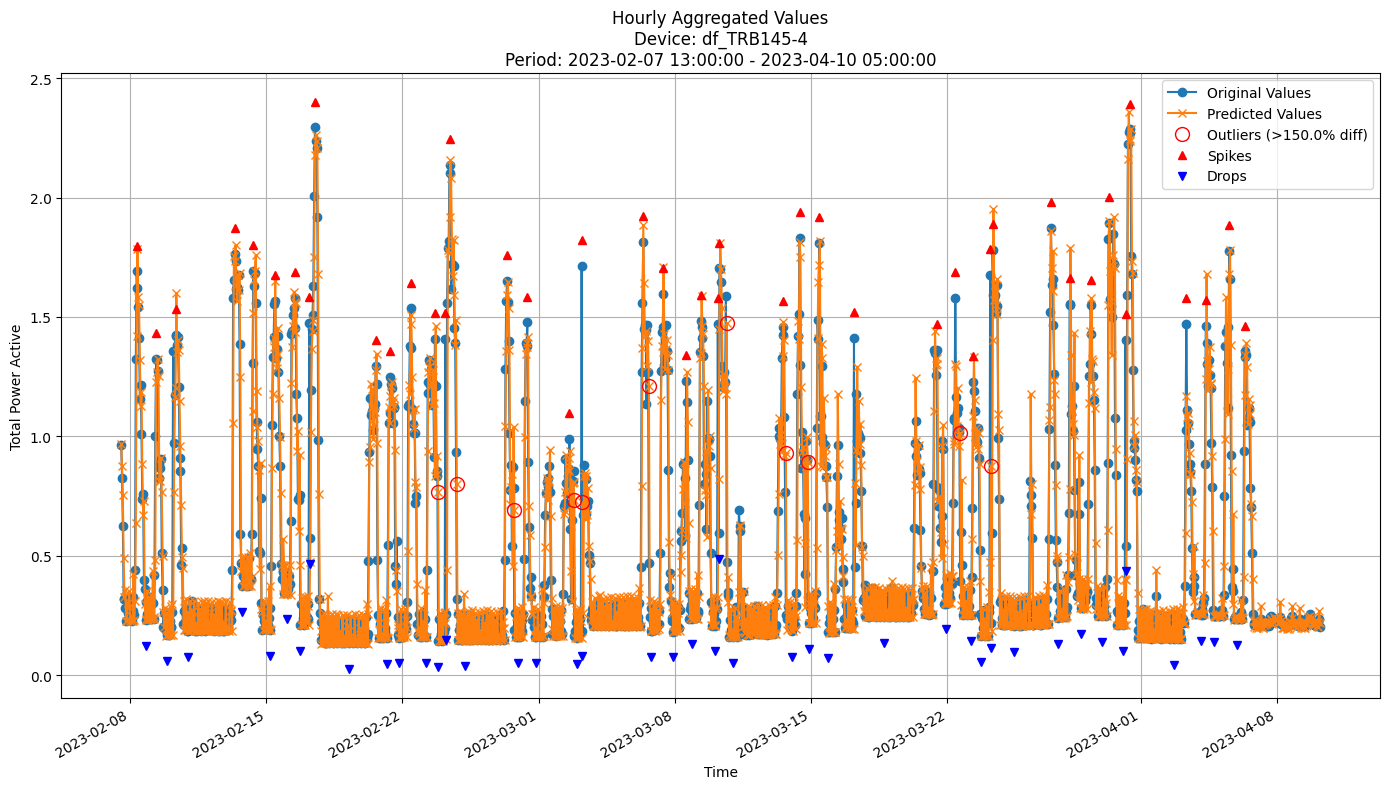


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1769
MAE: 0.0995
MAPE: 23.0789%

Directional Metrics:
Directional Accuracy: 55.8485%
First-Diff Correlation: 0.3984

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2368
  Recall: 0.2045
  F1 Score: 0.2195
Drops:
  Precision: 0.1351
  Recall: 0.1163
  F1 Score: 0.1250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7105
  Recall: 0.6136
  F1 Score: 0.6585
Drops:
  Precision: 0.5405
  Recall: 0.4651
  F1 Score: 0.5000


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [11]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 100,
    'learning_rate': 0.03,
    'subsample': 0.8,
    'max_depth': 10,
    'random_state': 42
}

In [12]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00

Time: 6.06 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 9.12 seconds
Predicting for chunk from 2022-11-01 13:15:00+01:00 to 2022-11-15 12:45:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3266
	MAE: 0.2064
	MAPE: 24.0856%

Directional Metrics:
	Directional Accuracy: 53.2564%
	First-Diff Correlation: 0.0778

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0588
		Recall: 0.0465
		F1: 0.0519
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00

Time: 12.38 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 15.77 seconds
Predicting for chunk from 2022-11-29 13:15:00+01:00 to 2022-12-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2801
	MAE: 0.1766
	MAPE: 34.5358%

Directional Metrics:
	Directional Accuracy: 52.0655%
	First-Diff Correlation: 0.1002

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00

Time: 39.87 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 43.61 seconds
Predicting for chunk from 2023-03-21 13:15:00+01:00 to 2023-04-04 13:45:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2406
	MAE: 0.1498
	MAPE: 34.1540%

Directional Metrics:
	Directional Accuracy: 52.2888%
	First-Diff Correlation: 0.0213

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0132
		Recall: 0.0233
		F1: 0.0168
	Drops:
		Precision: 0.0132
		Recall: 0.0233
		F1: 0.0168

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00

Time: 47.47 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1711
	MAE: 0.1193
	MAPE: 41.5738%

Directional Metrics:
	Directional Accuracy: 49.2620%
	First-Diff Correlation: 0.1973

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0714
		Recall: 0.0870
		F1: 0.0784
	Drops:
		Precision: 0.0357
		Recall: 0.0435
		F1: 0.0392

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1429
		Recall: 0.1739
		F1: 0.1569
	Drops:
		Precision: 0.1429
		Recall: 0.1739
		F1: 0.1569
--------------------------------------------------
Hourly Metrics:
----------------------------

#### Results

In [13]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.0577 ± 0.0125
	MAE: 0.0418 ± 0.0083
	MAPE: 9.8001% ± 2.2716%

	Directional Metrics:
		Directional Accuracy: 72.2894% ± 2.9669%
		First-Diff Correlation: 0.9239 ± 0.0395

	Immediate Detection (delta=0):
		Spike Precision: 0.6438 ± 0.1076
		Spike Recall: 0.5972 ± 0.1217
		Spike F1: 0.6186 ± 0.1115
		Drop Precision: 0.1508 ± 0.0868
		Drop Recall: 0.1436 ± 0.0949
		Drop F1: 0.1469 ± 0.0908

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8363 ± 0.0839
		Spike Recall: 0.7738 ± 0.1037
		Spike F1: 0.8027 ± 0.0886
		Drop Precision: 0.2756 ± 0.0930
		Drop Recall: 0.2591 ± 0.1078
		Drop F1: 0.2668 ± 0.1003
Hourly Metrics:
	RMSE: 0.0451 ± 0.0090
	MAE: 0.0328 ± 0.0058
	MAPE: 7.2311% ± 1.4827%

	Directional Metrics:
		Directional Accuracy: 90.7764% ± 1.6574%
		First-Diff Correlation: 0.9844 ± 0.0088

	Immediate Detection (delta=0):
		S

#### Training plots

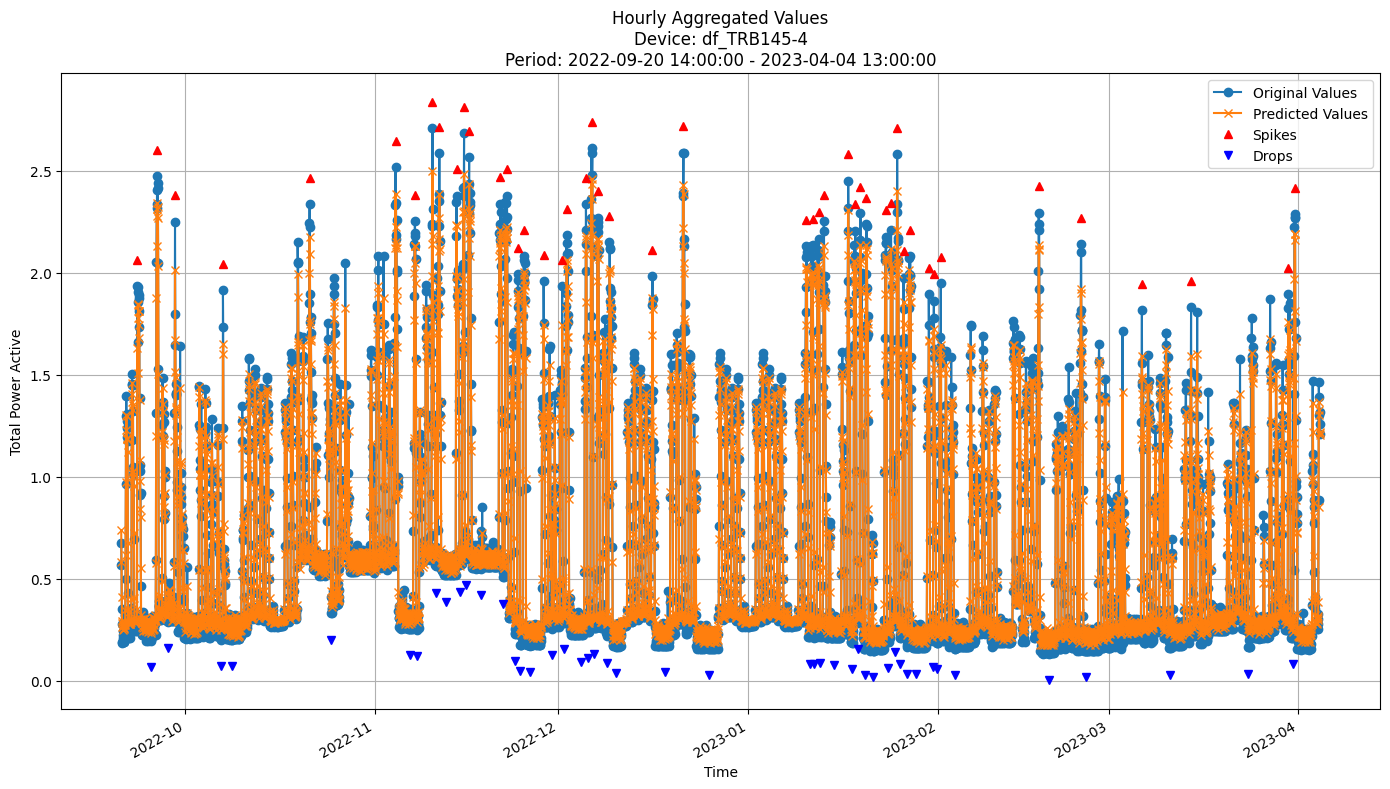


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0581
MAE: 0.0409
MAPE: 9.5112%

Directional Metrics:
Directional Accuracy: 88.5818%
First-Diff Correlation: 0.9694

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5968
  Recall: 0.7872
  F1 Score: 0.6789
Drops:
  Precision: 0.2459
  Recall: 0.3261
  F1 Score: 0.2804

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6613
  Recall: 0.8723
  F1 Score: 0.7523
Drops:
  Precision: 0.2459
  Recall: 0.3261
  F1 Score: 0.2804


In [14]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

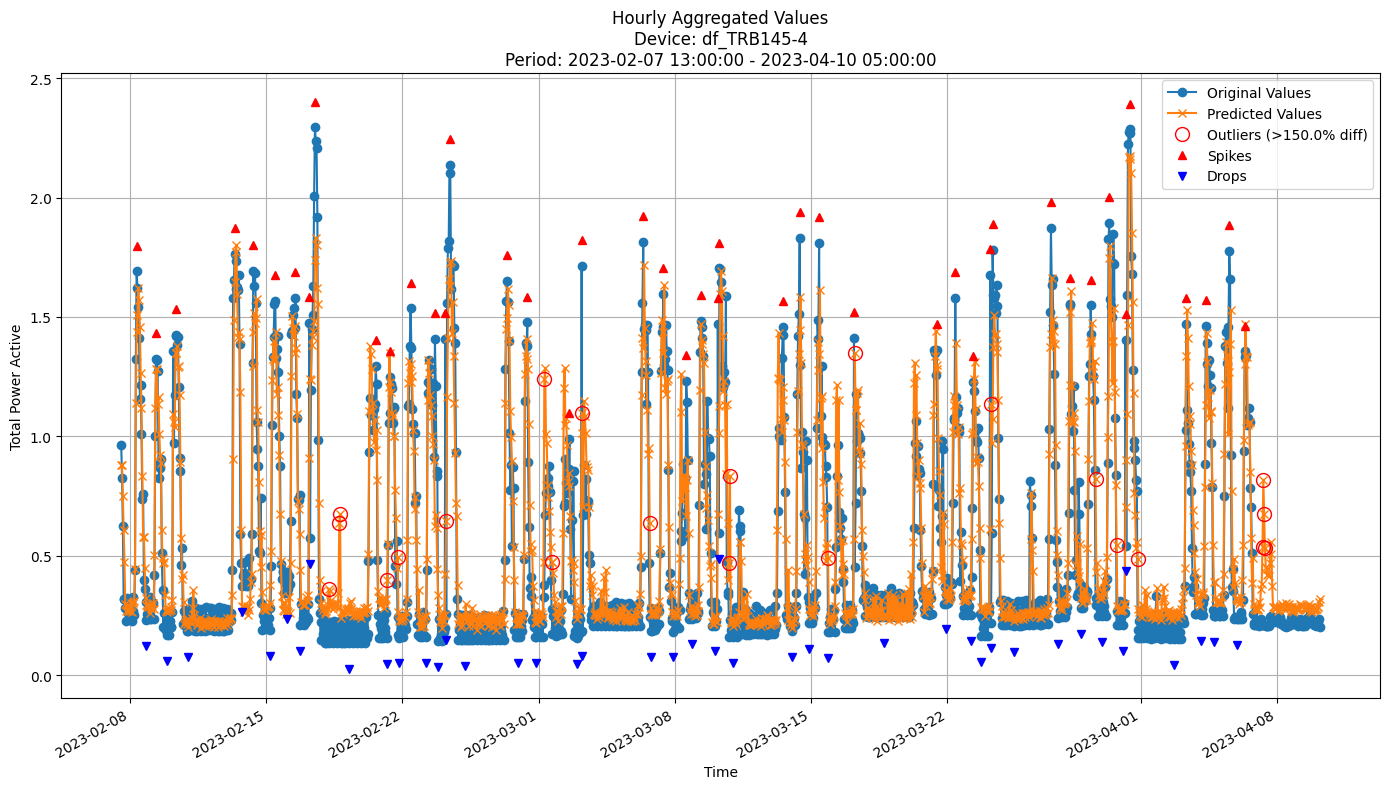


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1848
MAE: 0.1197
MAPE: 30.1510%

Directional Metrics:
Directional Accuracy: 59.9730%
First-Diff Correlation: 0.4065

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0455
  F1 Score: 0.0465
Drops:
  Precision: 0.1951
  Recall: 0.1860
  F1 Score: 0.1905

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.4773
  F1 Score: 0.4884
Drops:
  Precision: 0.2927
  Recall: 0.2791
  F1 Score: 0.2857


In [15]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# Basic Prediction Metrics:
# RMSE: 0.2195
# MAE: 0.1398
# MAPE: 33.6987%

### Random Forest model

In [16]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 100,
    'max_depth': 10,
    'max_features': 'sqrt',
    'random_state': 42,
    'n_jobs': -1
}

In [17]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00

Time: 0.16 seconds
Predicting for chunk from 2022-10-18 14:00:00+02:00 to 2022-11-01 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-01 13:00:00+01:00

Time: 0.20 seconds
Predicting for chunk from 2022-11-01 13:15:00+01:00 to 2022-11-15 12:45:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3029
	MAE: 0.1984
	MAPE: 23.7625%

Directional Metrics:
	Directional Accuracy: 55.0428%
	First-Diff Correlation: 0.0789

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0870
		Recall: 0.0465
		F1: 0.0606
	Drops:
		Precision: 0.0833
		Recall: 0.0455
		F1: 0.0588

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00

Time: 0.24 seconds
Predicting for chunk from 2022-11-15 13:00:00+01:00 to 2022-11-29 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2022-11-29 13:00:00+01:00

Time: 0.29 seconds
Predicting for chunk from 2022-11-29 13:15:00+01:00 to 2022-12-13 12:45:00+01:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2703
	MAE: 0.1663
	MAPE: 31.7431%

Directional Metrics:
	Directional Accuracy: 52.7726%
	First-Diff Correlation: 0.1053

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00

Time: 0.66 seconds
Predicting for chunk from 2023-03-07 13:00:00+01:00 to 2023-03-21 13:00:00+01:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-03-21 13:00:00+01:00

Time: 0.71 seconds
Predicting for chunk from 2023-03-21 13:15:00+01:00 to 2023-04-04 13:45:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2395
	MAE: 0.1494
	MAPE: 33.8760%

Directional Metrics:
	Directional Accuracy: 50.5396%
	First-Diff Correlation: 0.0588

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0323
		Recall: 0.0465
		F1: 0.0381
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00

Time: 0.79 seconds
Predicting for chunk from 2023-04-04 14:00:00+02:00 to 2023-04-10 05:30:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1482
	MAE: 0.0992
	MAPE: 31.2970%

Directional Metrics:
	Directional Accuracy: 53.6900%
	First-Diff Correlation: 0.1386

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0870
		F1: 0.0851
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.2609
		F1: 0.2553
	Drops:
		Precision: 0.2400
		Recall: 0.2609
		F1: 0.2500
--------------------------------------------------
Hourly Metrics:
-----------------------------

#### Results

In [18]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.1188 ± 0.0161
	MAE: 0.0704 ± 0.0112
	MAPE: 13.9615% ± 2.7559%

	Directional Metrics:
		Directional Accuracy: 65.5089% ± 1.9865%
		First-Diff Correlation: 0.7042 ± 0.0718

	Immediate Detection (delta=0):
		Spike Precision: 0.3514 ± 0.0753
		Spike Recall: 0.2917 ± 0.0782
		Spike F1: 0.3174 ± 0.0753
		Drop Precision: 0.0633 ± 0.0377
		Drop Recall: 0.0546 ± 0.0413
		Drop F1: 0.0582 ± 0.0391

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5550 ± 0.0956
		Spike Recall: 0.4645 ± 0.1317
		Spike F1: 0.5034 ± 0.1132
		Drop Precision: 0.1758 ± 0.0800
		Drop Recall: 0.1518 ± 0.0971
		Drop F1: 0.1618 ± 0.0882
Hourly Metrics:
	RMSE: 0.0963 ± 0.0149
	MAE: 0.0558 ± 0.0095
	MAPE: 10.3422% ± 2.0917%

	Directional Metrics:
		Directional Accuracy: 80.1689% ± 2.6167%
		First-Diff Correlation: 0.8643 ± 0.0396

	Immediate Detection (delta=0):
	

#### Training plots
Plot only the last period of predictions

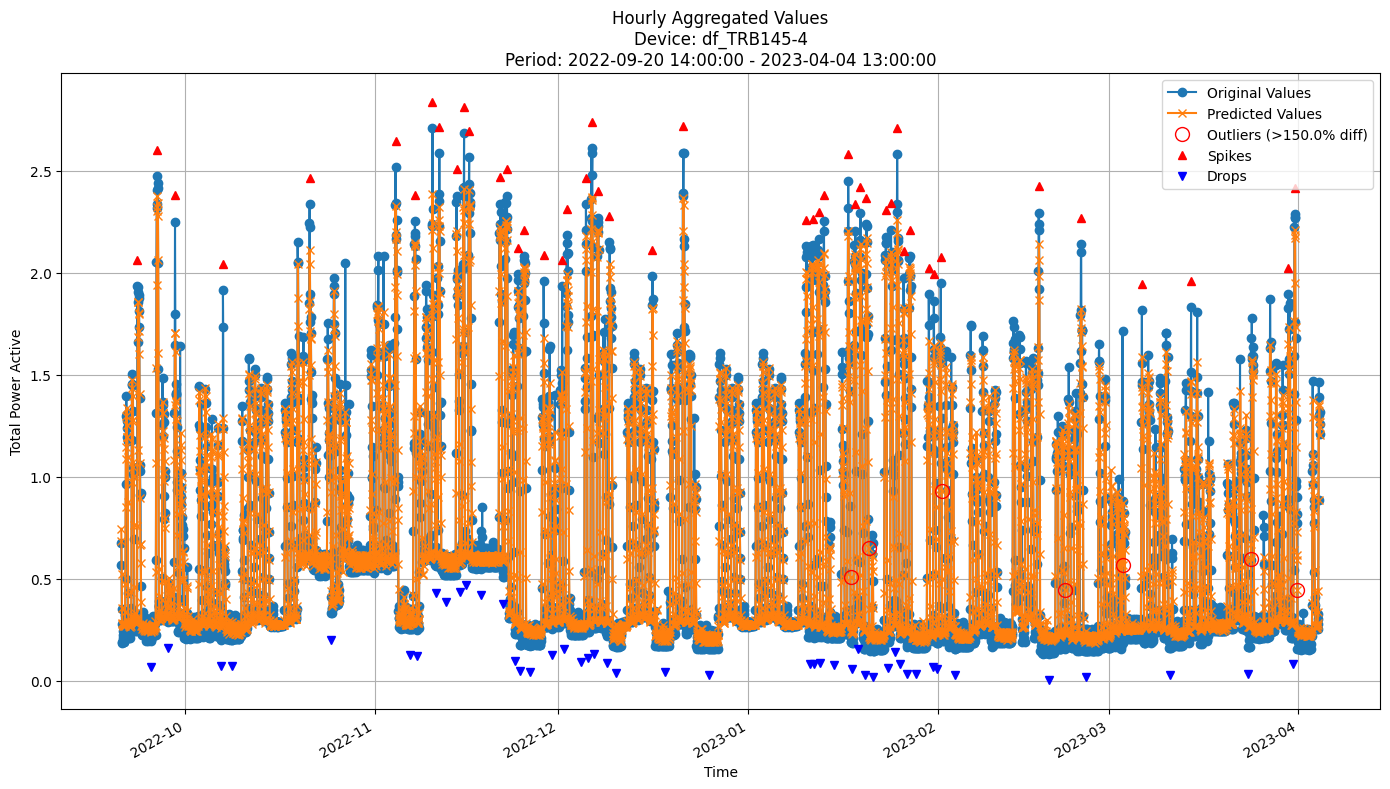


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1178
MAE: 0.0693
MAPE: 13.9332%

Directional Metrics:
Directional Accuracy: 75.6113%
First-Diff Correlation: 0.7970

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3556
  Recall: 0.3404
  F1 Score: 0.3478
Drops:
  Precision: 0.0909
  Recall: 0.0870
  F1 Score: 0.0889

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7333
  Recall: 0.7021
  F1 Score: 0.7174
Drops:
  Precision: 0.1364
  Recall: 0.1304
  F1 Score: 0.1333


In [19]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

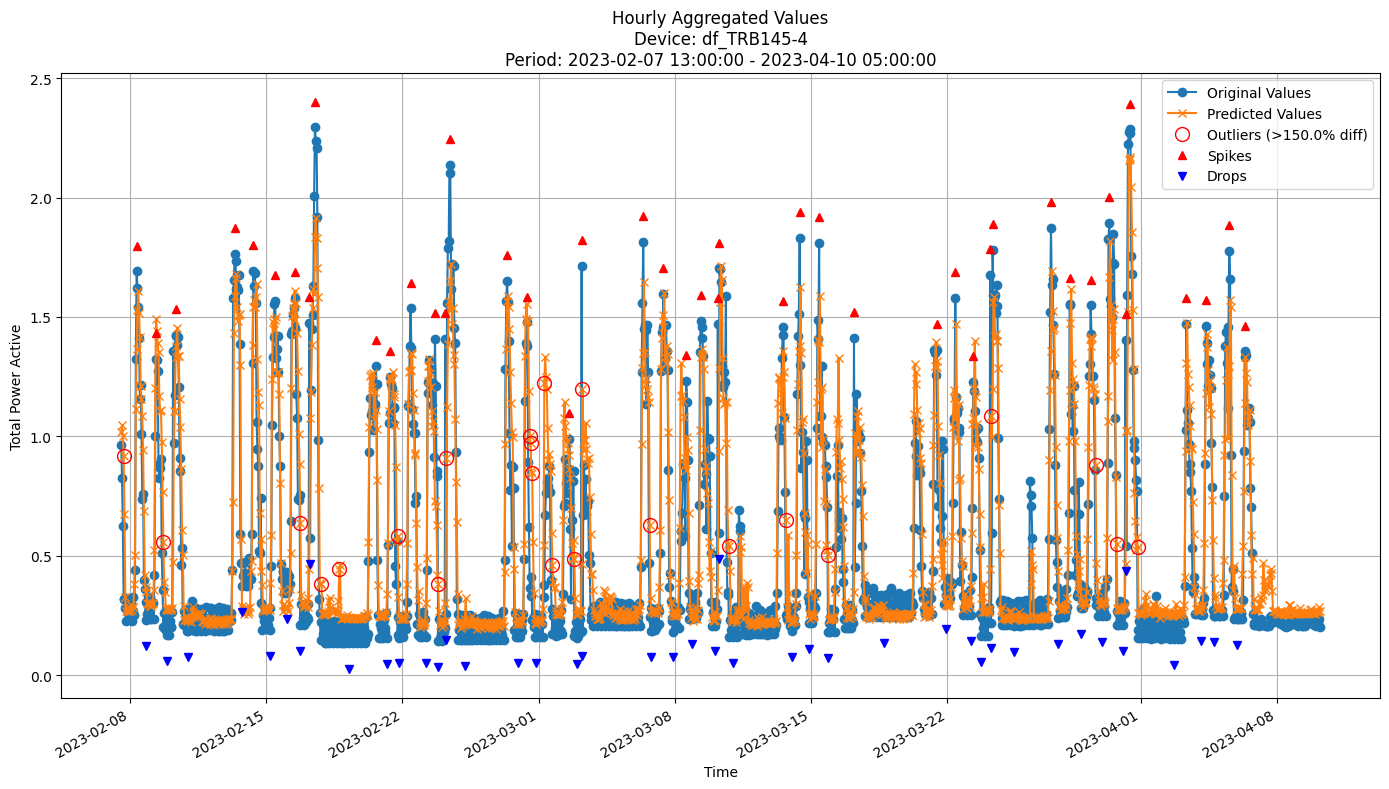


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2008
MAE: 0.1255
MAPE: 30.4049%

Directional Metrics:
Directional Accuracy: 57.8093%
First-Diff Correlation: 0.2936

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0455
  F1 Score: 0.0465
Drops:
  Precision: 0.0952
  Recall: 0.0930
  F1 Score: 0.0941

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5476
  Recall: 0.5227
  F1 Score: 0.5349
Drops:
  Precision: 0.3095
  Recall: 0.3023
  F1 Score: 0.3059


In [20]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [ ]:
update_freq = "15m"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'grace_period': 10,
    'delta': 0.5,
    'max_depth': 10,
    'tau': 0.05,
    'leaf_prediction': 'mean'
}

In [22]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4696
	MAE: 0.3458
	MAPE: 41.8923%

Directional Metrics:
	Directional Accuracy: 23.6695%
	First-Diff Correlation: -0.0022

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4012
	MAE: 0.2618
	MAPE: 46.6021%

Directional Metrics:
	Directional Accuracy: 23.9300%
	First-Diff Correlation: 0.0437


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3397
	MAE: 0.2229
	MAPE: 53.2315%

Directional Metrics:
	Directional Accuracy: 25.6048%
	First-Diff Correlation: 0.0460


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1791
	MAE: 0.1118
	MAPE: 33.0014%

Directional Metrics:
	Directional Accuracy: 24.9077%
	First-Diff Correlation: 0.0845


#### Results

In [23]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.3276 ± 0.0241
	MAE: 0.2077 ± 0.0230
	MAPE: 38.5728% ± 3.6284%

	Directional Metrics:
		Directional Accuracy: 20.1523% ± 1.4014%
		First-Diff Correlation: 0.0415 ± 0.0073

	Immediate Detection (delta=0):
		Spike Precision: 0.0106 ± 0.0090
		Spike Recall: 0.0308 ± 0.0251
		Spike F1: 0.0156 ± 0.0130
		Drop Precision: 0.0149 ± 0.0047
		Drop Recall: 0.0456 ± 0.0116
		Drop F1: 0.0224 ± 0.0068

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0611 ± 0.0154
		Spike Recall: 0.1716 ± 0.0326
		Spike F1: 0.0896 ± 0.0210
		Drop Precision: 0.0457 ± 0.0099
		Drop Recall: 0.1457 ± 0.0307
		Drop F1: 0.0691 ± 0.0140
Hourly Metrics:
	RMSE: 0.2849 ± 0.0196
	MAE: 0.1844 ± 0.0207
	MAPE: 33.2812% ± 3.5144%

	Directional Metrics:
		Directional Accuracy: 48.6014% ± 0.6793%
		First-Diff Correlation: 0.2806 ± 0.0478

	Immediate Detection (delta=0):
	

#### Training plots
Plot only the last period of predictions

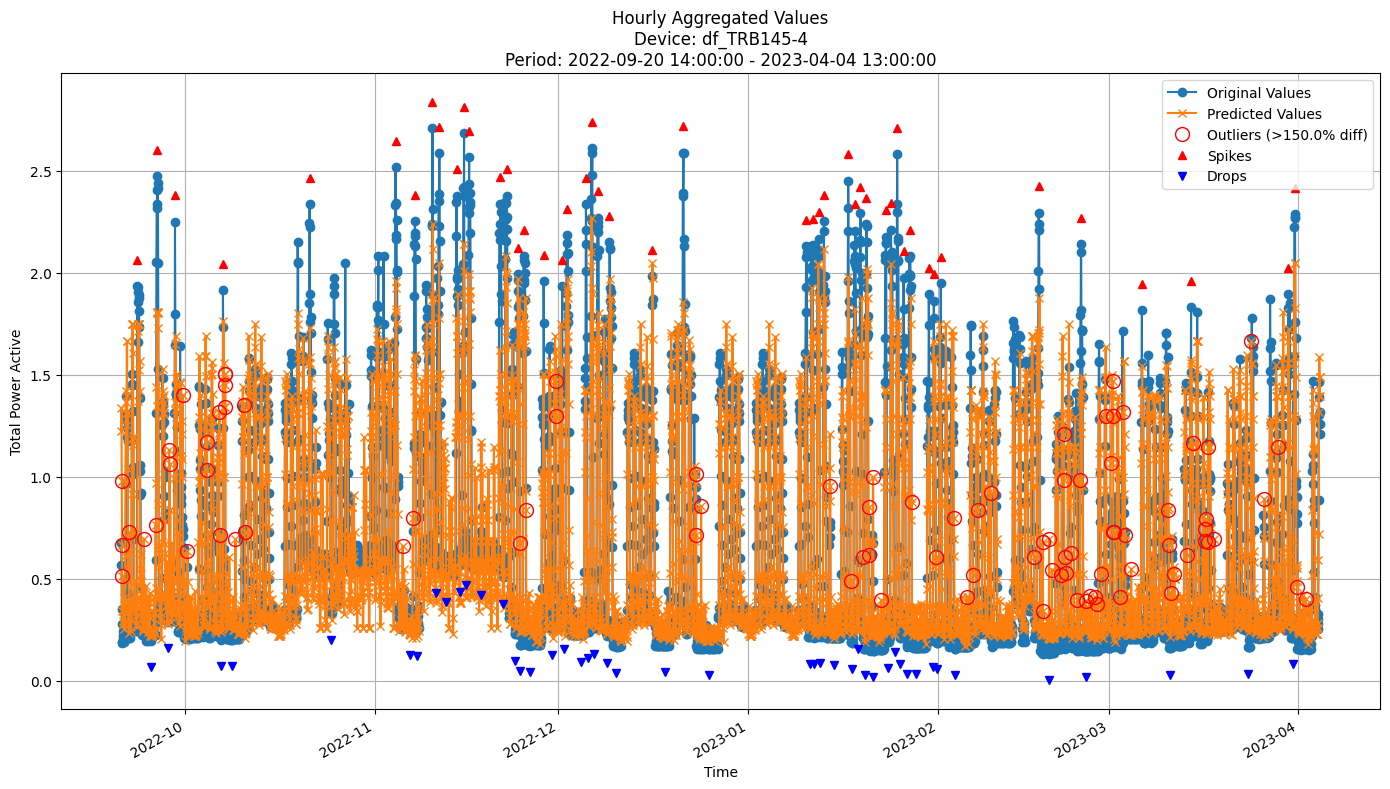


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2759
MAE: 0.1781
MAPE: 33.2069%

Directional Metrics:
Directional Accuracy: 48.3946%
First-Diff Correlation: 0.2903

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2381
  Recall: 0.1064
  F1 Score: 0.1471
Drops:
  Precision: 0.1304
  Recall: 0.0652
  F1 Score: 0.0870

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4762
  Recall: 0.2128
  F1 Score: 0.2941
Drops:
  Precision: 0.2174
  Recall: 0.1087
  F1 Score: 0.1449


In [24]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

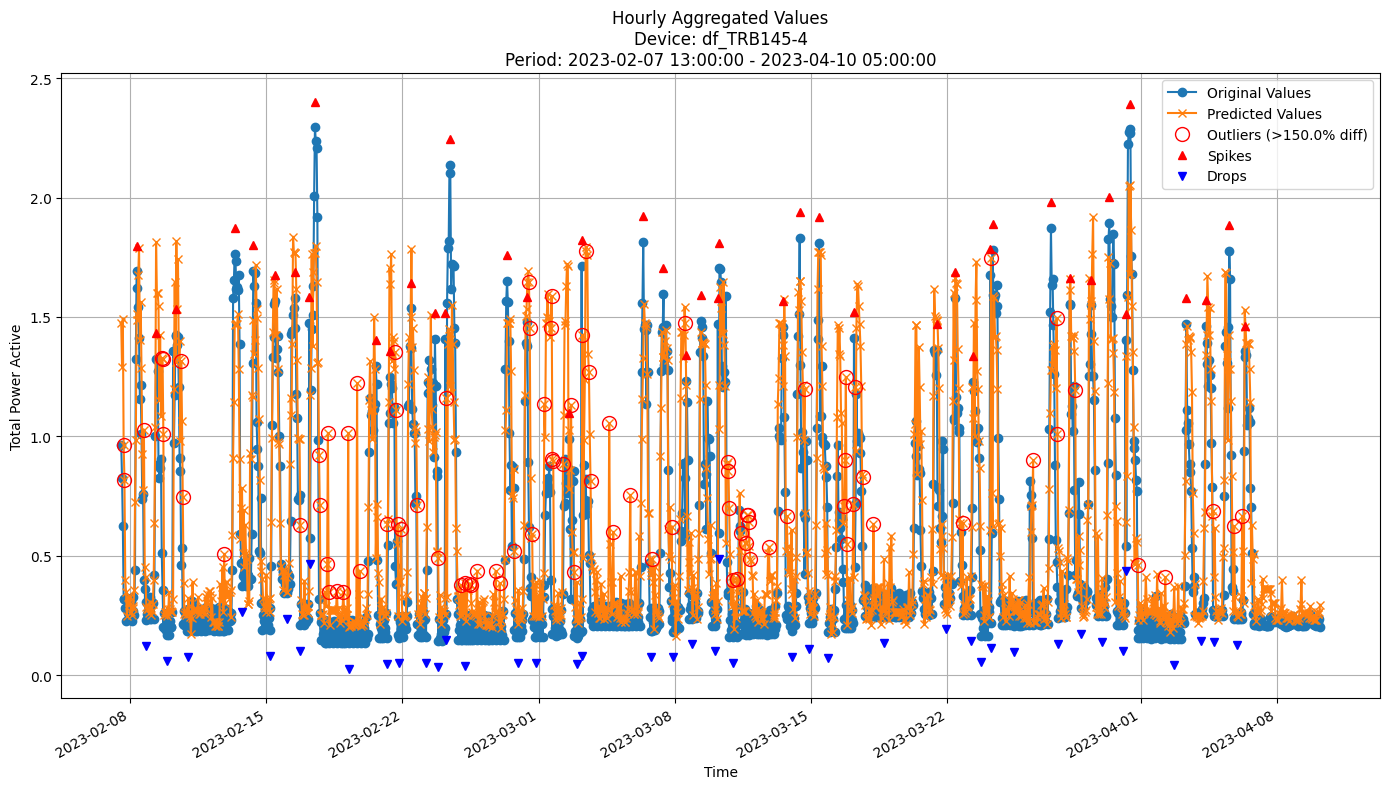


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2931
MAE: 0.1915
MAPE: 48.3654%

Directional Metrics:
Directional Accuracy: 48.8168%
First-Diff Correlation: 0.1287

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.1136
  F1 Score: 0.1190
Drops:
  Precision: 0.0250
  Recall: 0.0233
  F1 Score: 0.0241

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4250
  Recall: 0.3864
  F1 Score: 0.4048
Drops:
  Precision: 0.1750
  Recall: 0.1628
  F1 Score: 0.1687


In [25]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [ ]:
update_freq = "15m"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 10,
    'max_features': 0.8,
    'aggregation_method': 'median',
    'grace_period': 10,
    'max_depth': 10,
    'delta': 0.5,  # split confidence
    'tau': 0.01,  # break ties
    'seed': 42
}

In [27]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4028
	MAE: 0.2889
	MAPE: 31.8783%

Directional Metrics:
	Directional Accuracy: 42.7987%
	First-Diff Correlation: 0.0480


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3355
	MAE: 0.2240
	MAPE: 42.0980%

Directional Metrics:
	Directional Accuracy: 43.8779%
	First-Diff Correlation: 0.0583


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2810
	MAE: 0.1919
	MAPE: 46.7492%

Directional Metrics:
	Directional Accuracy: 42.2032%
	First-Diff Correlation: 0.0439


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1444
	MAE: 0.1097
	MAPE: 38.4010%

Directional Metrics:
	Directional Accuracy: 44.8339%
	First-Diff Correlation: 0.2117


#### Results

In [28]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.2744 ± 0.0083
	MAE: 0.1743 ± 0.0130
	MAPE: 33.8828% ± 2.4269%

	Directional Metrics:
		Directional Accuracy: 44.9021% ± 0.9681%
		First-Diff Correlation: 0.1244 ± 0.0106

	Immediate Detection (delta=0):
		Spike Precision: 0.0644 ± 0.0073
		Spike Recall: 0.0860 ± 0.0173
		Spike F1: 0.0722 ± 0.0041
		Drop Precision: 0.0164 ± 0.0068
		Drop Recall: 0.0244 ± 0.0167
		Drop F1: 0.0193 ± 0.0101

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1503 ± 0.0216
		Spike Recall: 0.2058 ± 0.0717
		Spike F1: 0.1700 ± 0.0305
		Drop Precision: 0.0520 ± 0.0184
		Drop Recall: 0.0760 ± 0.0463
		Drop F1: 0.0608 ± 0.0276
Hourly Metrics:
	RMSE: 0.2496 ± 0.0075
	MAE: 0.1615 ± 0.0133
	MAPE: 30.3136% ± 2.7826%

	Directional Metrics:
		Directional Accuracy: 59.1245% ± 1.9497%
		First-Diff Correlation: 0.4614 ± 0.0375

	Immediate Detection (delta=0):
	

#### Training plots

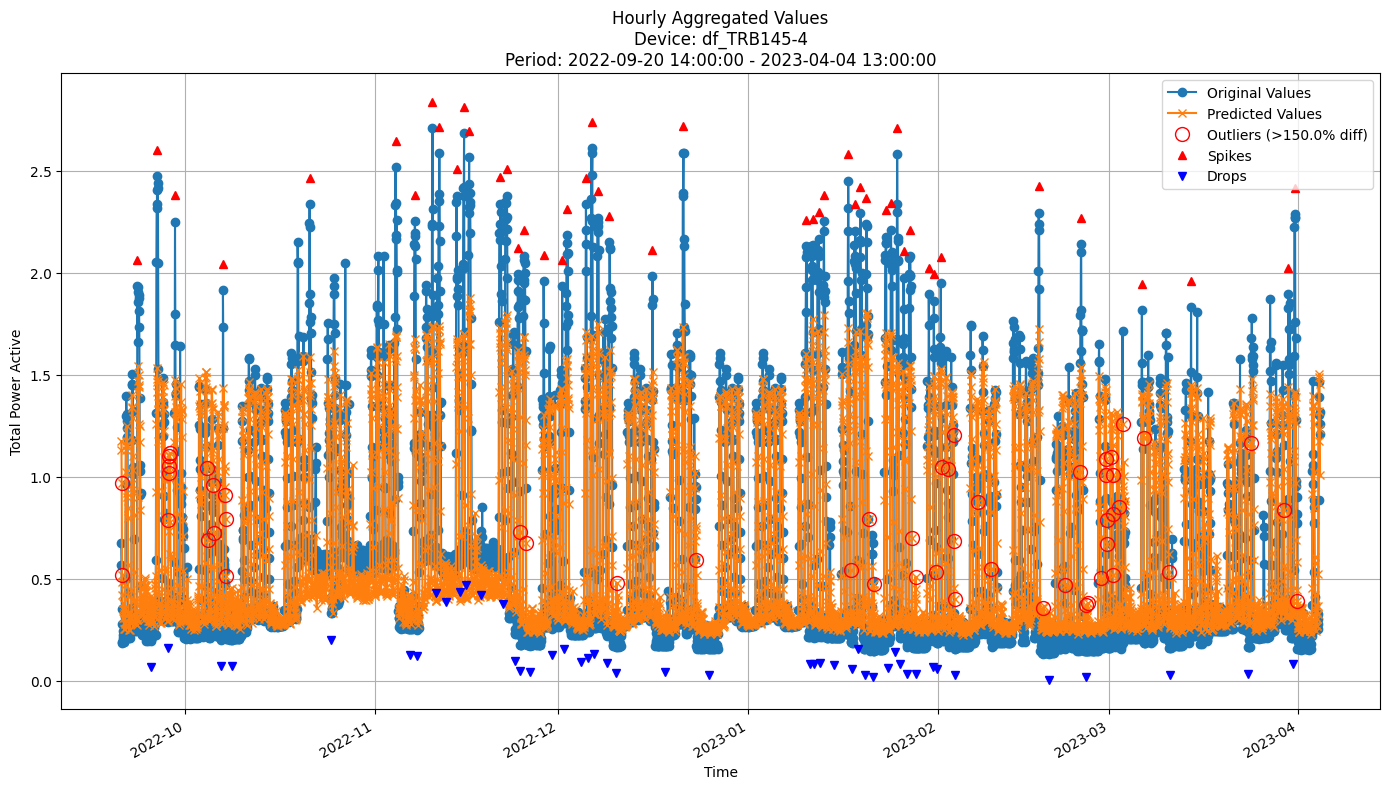


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2442
MAE: 0.1566
MAPE: 29.6698%

Directional Metrics:
Directional Accuracy: 56.6872%
First-Diff Correlation: 0.4595

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2407
  Recall: 0.2766
  F1 Score: 0.2574
Drops:
  Precision: 0.0370
  Recall: 0.0435
  F1 Score: 0.0400

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4630
  Recall: 0.5319
  F1 Score: 0.4950
Drops:
  Precision: 0.1296
  Recall: 0.1522
  F1 Score: 0.1400


In [29]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

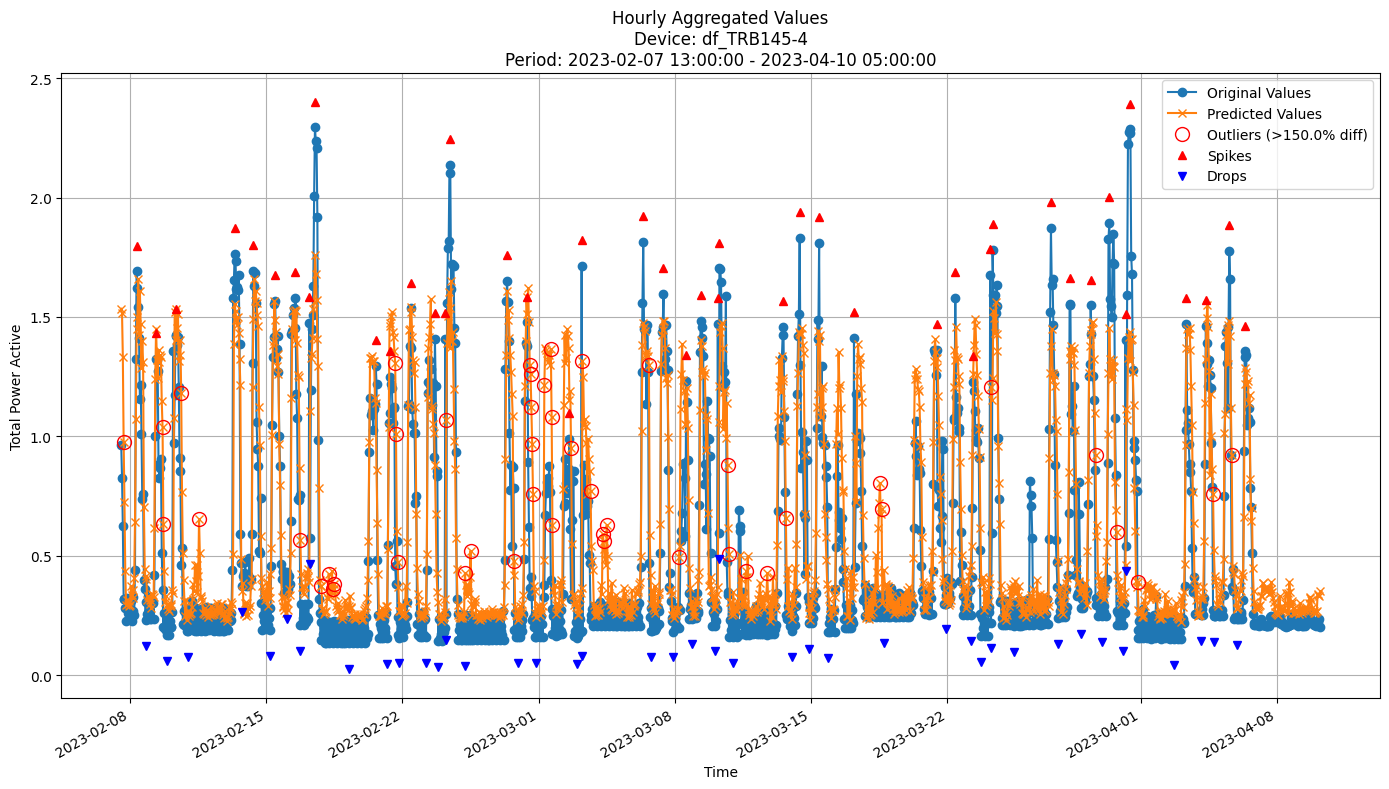


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2518
MAE: 0.1703
MAPE: 43.9759%

Directional Metrics:
Directional Accuracy: 49.0196%
First-Diff Correlation: 0.2488

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2381
  Recall: 0.2273
  F1 Score: 0.2326
Drops:
  Precision: 0.0238
  Recall: 0.0233
  F1 Score: 0.0235

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5238
  Recall: 0.5000
  F1 Score: 0.5116
Drops:
  Precision: 0.1905
  Recall: 0.1860
  F1 Score: 0.1882


In [30]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [ ]:
update_freq = "15m"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
    "depth": 50,
    "grace_period": 10,
    "split_confidence": 0.005,
    "option": 'hf',
    "eagerness": 1000,
    "grace_period_depth": 0
}

In [32]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5327
	MAE: 0.3823
	MAPE: 38.7479%

Directional Metrics:
	Directional Accuracy: 39.8586%
	First-Diff Correlation: 0.0853


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5308
	MAE: 0.3560
	MAPE: 48.2468%

Directional Metrics:
	Directional Accuracy: 38.4071%
	First-Diff Correlation: 0.0494


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3133
	MAE: 0.2328
	MAPE: 61.5359%

Directional Metrics:
	Directional Accuracy: 36.6580%
	First-Diff Correlation: 0.0437


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2053
	MAE: 0.1774
	MAPE: 65.6050%

Directional Metrics:
	Directional Accuracy: 42.6199%
	First-Diff Correlation: 0.1494


#### Results

In [33]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.3919 ± 0.0324
	MAE: 0.2633 ± 0.0266
	MAPE: 44.4415% ± 5.1392%

	Directional Metrics:
		Directional Accuracy: 37.5942% ± 1.1909%
		First-Diff Correlation: 0.0678 ± 0.0113

	Immediate Detection (delta=0):
		Spike Precision: 0.0157 ± 0.0076
		Spike Recall: 0.0320 ± 0.0179
		Spike F1: 0.0210 ± 0.0106
		Drop Precision: 0.0185 ± 0.0079
		Drop Recall: 0.0440 ± 0.0186
		Drop F1: 0.0259 ± 0.0109

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0644 ± 0.0137
		Spike Recall: 0.1306 ± 0.0330
		Spike F1: 0.0855 ± 0.0185
		Drop Precision: 0.0428 ± 0.0125
		Drop Recall: 0.1019 ± 0.0242
		Drop F1: 0.0600 ± 0.0163
Hourly Metrics:
	RMSE: 0.3749 ± 0.0332
	MAE: 0.2553 ± 0.0273
	MAPE: 41.5742% ± 4.6778%

	Directional Metrics:
		Directional Accuracy: 57.3174% ± 0.9595%
		First-Diff Correlation: 0.4082 ± 0.0227

	Immediate Detection (delta=0):
	

#### Training plots


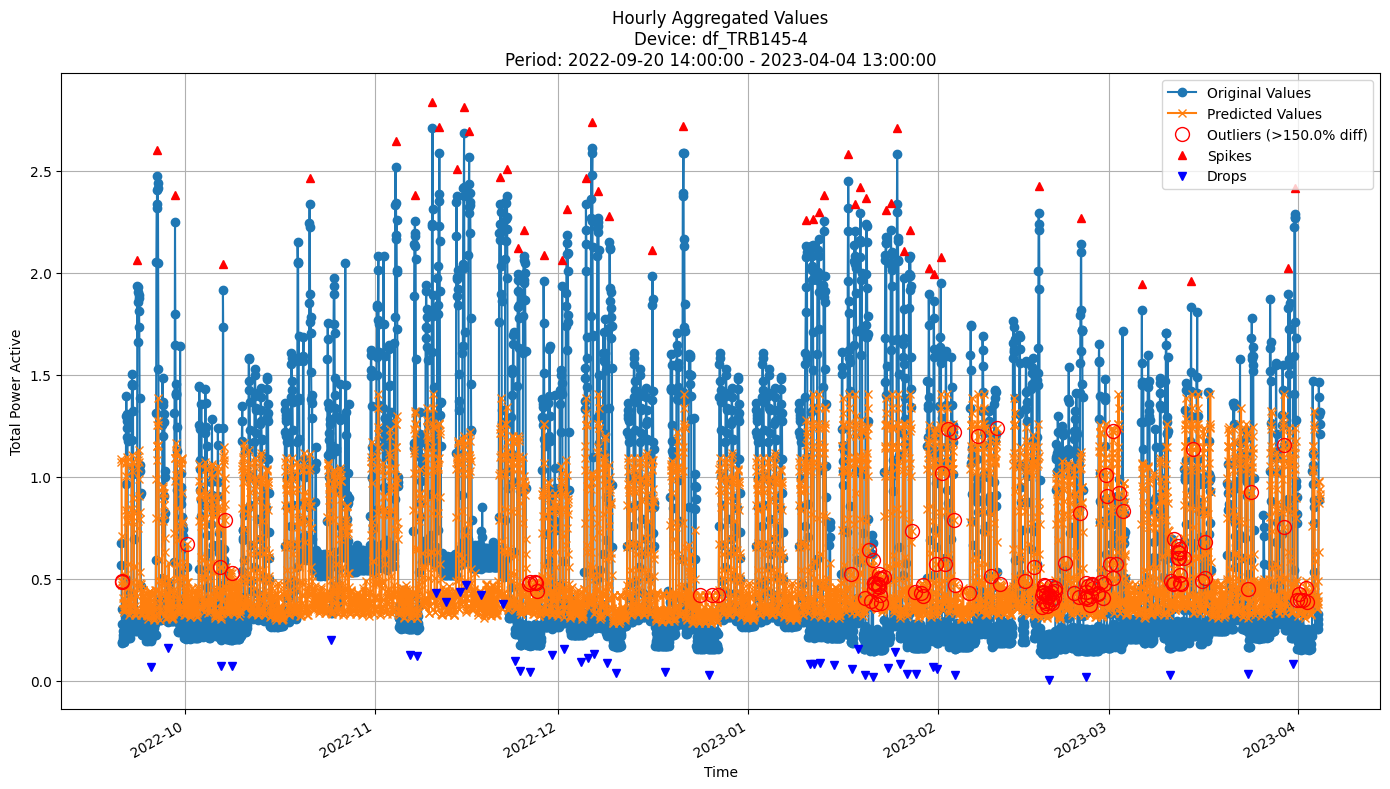


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3652
MAE: 0.2556
MAPE: 48.7490%

Directional Metrics:
Directional Accuracy: 55.7942%
First-Diff Correlation: 0.3938

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0769
  Recall: 0.1277
  F1 Score: 0.0960
Drops:
  Precision: 0.0471
  Recall: 0.0870
  F1 Score: 0.0611

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2436
  Recall: 0.4043
  F1 Score: 0.3040
Drops:
  Precision: 0.1176
  Recall: 0.2174
  F1 Score: 0.1527


In [34]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

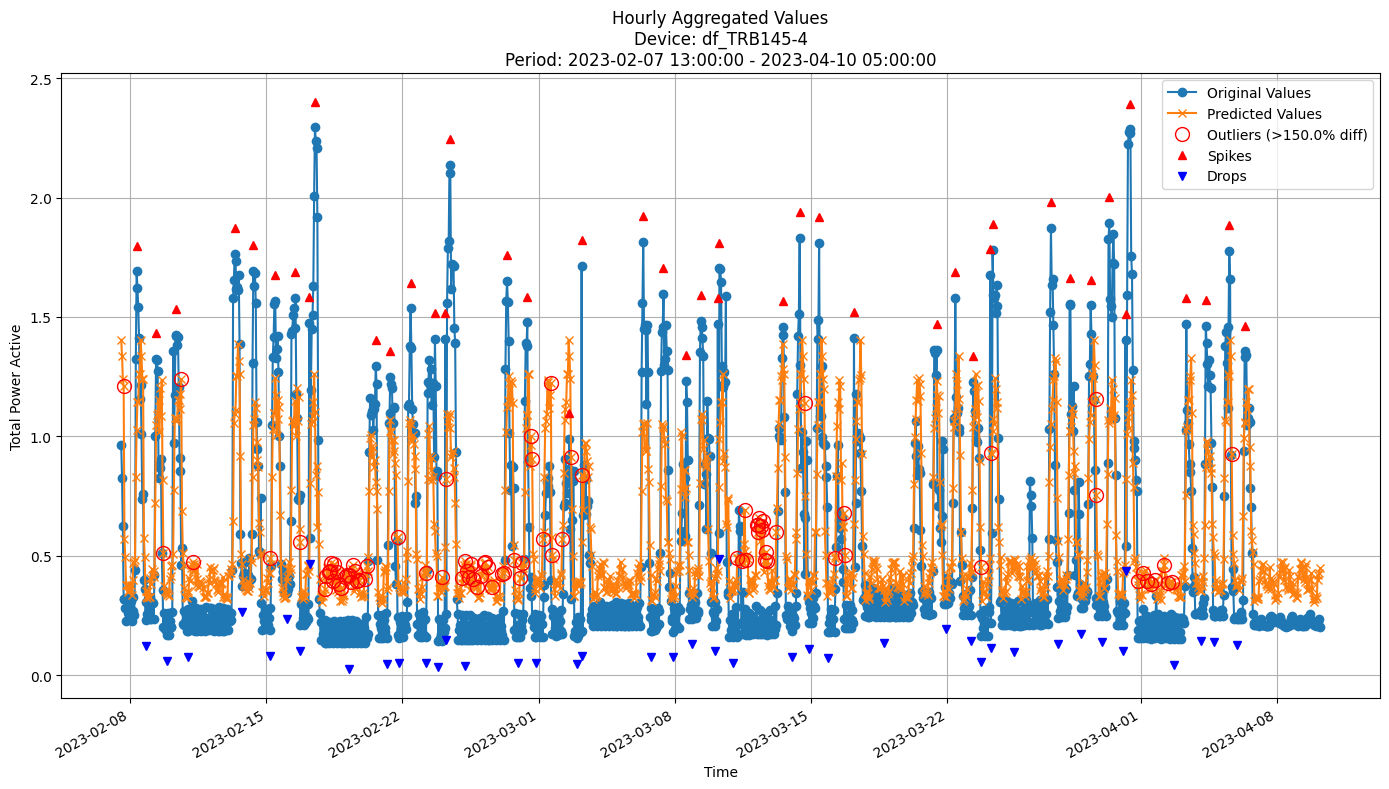


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2910
MAE: 0.2268
MAPE: 63.4500%

Directional Metrics:
Directional Accuracy: 52.1974%
First-Diff Correlation: 0.2860

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0690
  Recall: 0.0455
  F1 Score: 0.0548
Drops:
  Precision: 0.0345
  Recall: 0.0233
  F1 Score: 0.0278

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2759
  Recall: 0.1818
  F1 Score: 0.2192
Drops:
  Precision: 0.2414
  Recall: 0.1628
  F1 Score: 0.1944


In [35]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [ ]:
update_freq = "15m"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    "n_models": 20,
    "aggregation_method": "mean",
    "grace_period": 0,  # by default works for all leaves
    "max_depth": 100,
    "delta": 0.005,  # split confidence
    "tau": 0.01,  # break ties
    "seed": 42,
    "max_feature": 0.7,  # maximum feature ratio for each model
    "eagerness": 200
}

In [37]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4167
	MAE: 0.2866
	MAPE: 36.9246%

Directional Metrics:
	Directional Accuracy: 50.0558%
	First-Diff Correlation: 0.0378


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4526
	MAE: 0.3851
	MAPE: 98.2585%

Directional Metrics:
	Directional Accuracy: 48.7533%
	First-Diff Correlation: 0.0841


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2907
	MAE: 0.2136
	MAPE: 56.2525%

Directional Metrics:
	Directional Accuracy: 48.0461%
	First-Diff Correlation: 0.0723


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2376
	MAE: 0.2097
	MAPE: 79.7038%

Directional Metrics:
	Directional Accuracy: 49.8155%
	First-Diff Correlation: 0.0922


#### Results

In [38]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.4095 ± 0.0494
	MAE: 0.2943 ± 0.0623
	MAPE: 59.7280% ± 24.6563%

	Directional Metrics:
		Directional Accuracy: 50.0796% ± 0.6584%
		First-Diff Correlation: 0.0700 ± 0.0148

	Immediate Detection (delta=0):
		Spike Precision: 0.0283 ± 0.0185
		Spike Recall: 0.0504 ± 0.0194
		Spike F1: 0.0338 ± 0.0156
		Drop Precision: 0.0151 ± 0.0096
		Drop Recall: 0.0273 ± 0.0153
		Drop F1: 0.0180 ± 0.0089

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0647 ± 0.0180
		Spike Recall: 0.1241 ± 0.0480
		Spike F1: 0.0809 ± 0.0227
		Drop Precision: 0.0344 ± 0.0106
		Drop Recall: 0.0699 ± 0.0336
		Drop F1: 0.0430 ± 0.0100
Hourly Metrics:
	RMSE: 0.3930 ± 0.0518
	MAE: 0.2858 ± 0.0622
	MAPE: 56.4372% ± 24.2251%

	Directional Metrics:
		Directional Accuracy: 58.8973% ± 1.0851%
		First-Diff Correlation: 0.4211 ± 0.0483

	Immediate Detection (delta=0):

#### Training plots

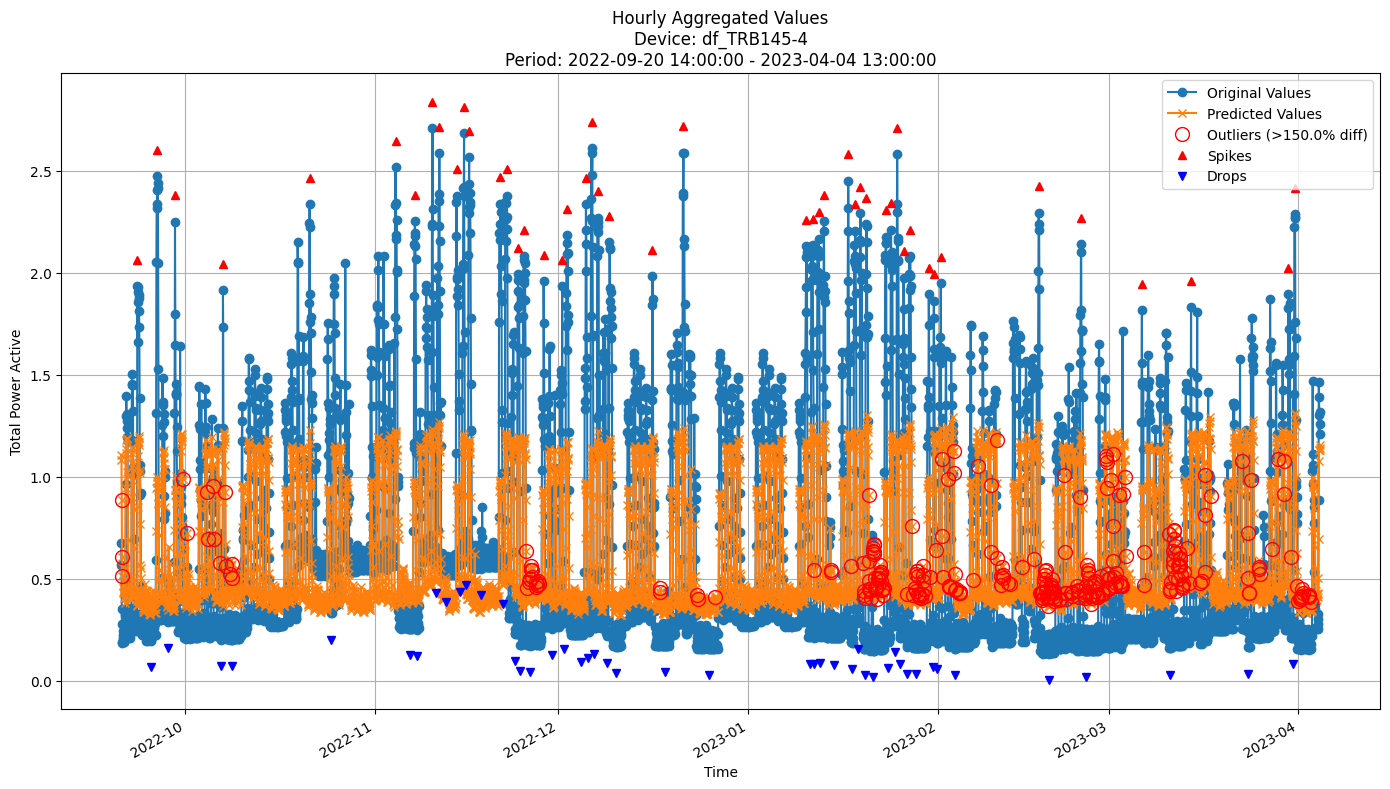


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3640
MAE: 0.2669
MAPE: 57.6848%

Directional Metrics:
Directional Accuracy: 57.2826%
First-Diff Correlation: 0.4248

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0392
  Recall: 0.0851
  F1 Score: 0.0537
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1569
  Recall: 0.3404
  F1 Score: 0.2148
Drops:
  Precision: 0.0388
  Recall: 0.0870
  F1 Score: 0.0537


In [39]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

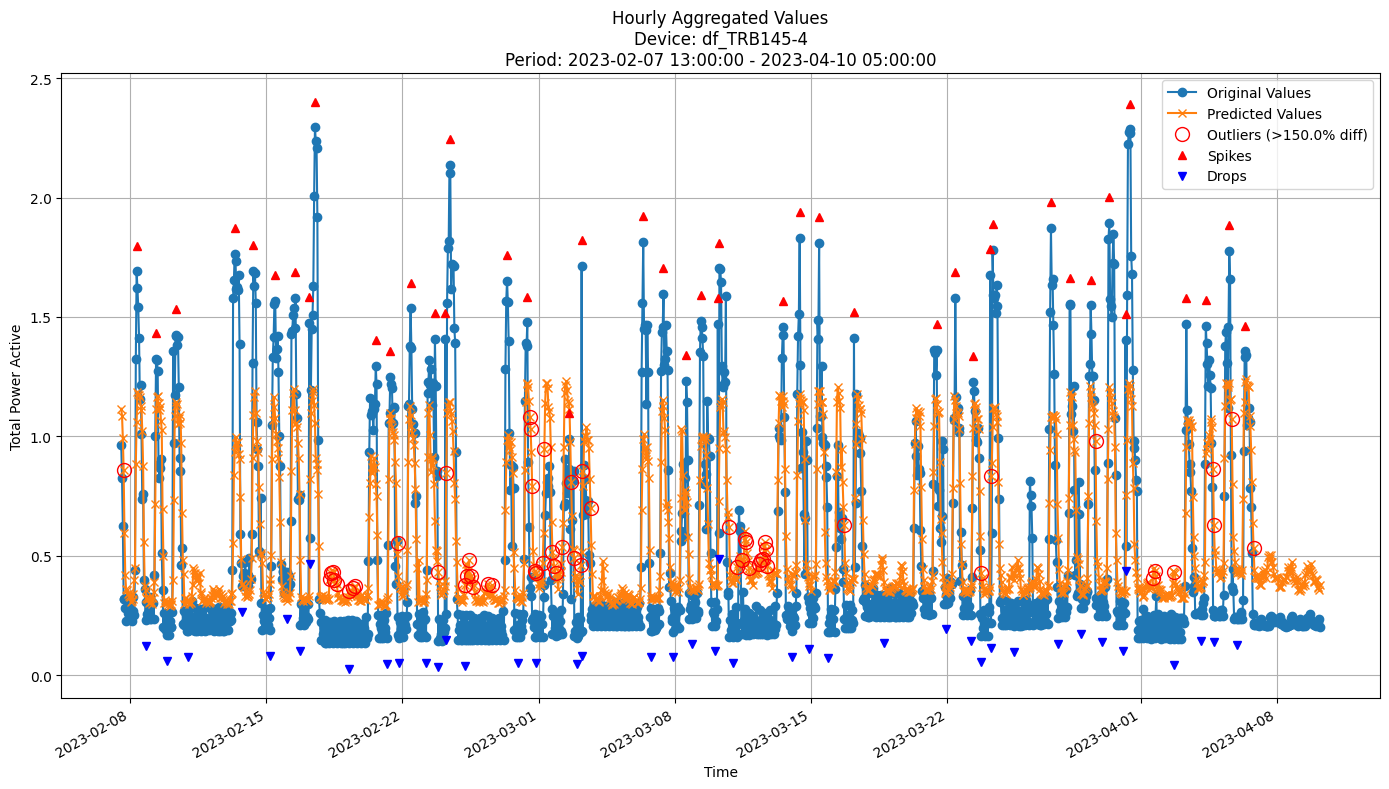


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2750
MAE: 0.2071
MAPE: 56.5393%

Directional Metrics:
Directional Accuracy: 57.5389%
First-Diff Correlation: 0.3624

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1724
  Recall: 0.1136
  F1 Score: 0.1370
Drops:
  Precision: 0.0345
  Recall: 0.0233
  F1 Score: 0.0278

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4828
  Recall: 0.3182
  F1 Score: 0.3836
Drops:
  Precision: 0.1724
  Recall: 0.1163
  F1 Score: 0.1389


In [40]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [ ]:
update_freq = "15m"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.01
n_trees = 100
grace_period = 0
depth = 50
eagerness = 1000
learning_rate = 0.5
max_features = 1.0
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
incb = IncubationBoost
incb_params = {
    "baseLearner": fastodt.FastODT,
    "length": n_trees,
    "learning_rate": learning_rate,
    "incubationMode": "DEFAULT",
    "verbose": False,
    "baseLearnerOptions": (depth, grace_period, split_confidence_hf, "hf", max_features, eagerness, grace_period_depth),
}

In [42]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,  
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-10-18 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-10-18 14:00:00+02:00 - 2022-11-15 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7031
	MAE: 0.5764
	MAPE: 64.8057%

Directional Metrics:
	Directional Accuracy: 34.5367%
	First-Diff Correlation: 0.0811


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2022-11-15 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 13:00:00+01:00 - 2022-12-13 12:45:00+01:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6786
	MAE: 0.4653
	MAPE: 49.6080%

Directional Metrics:
	Directional Accuracy: 37.0674%
	First-Diff Correlation: 0.0870


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-03-07 12:45:00+01:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-03-07 13:00:00+01:00 - 2023-04-04 13:45:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3168
	MAE: 0.2031
	MAPE: 43.1584%

Directional Metrics:
	Directional Accuracy: 36.1370%
	First-Diff Correlation: 0.0465


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-04 13:45:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1811
	MAE: 0.1109
	MAPE: 32.7818%

Directional Metrics:
	Directional Accuracy: 34.3173%
	First-Diff Correlation: 0.0851


#### Results

In [43]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
15m Metrics:
	RMSE: 0.4638 ± 0.0753
	MAE: 0.3108 ± 0.0659
	MAPE: 42.0733% ± 5.5303%

	Directional Metrics:
		Directional Accuracy: 35.8134% ± 1.0183%
		First-Diff Correlation: 0.0768 ± 0.0045

	Immediate Detection (delta=0):
		Spike Precision: 0.0113 ± 0.0051
		Spike Recall: 0.0278 ± 0.0260
		Spike F1: 0.0155 ± 0.0084
		Drop Precision: 0.0107 ± 0.0093
		Drop Recall: 0.0356 ± 0.0462
		Drop F1: 0.0161 ± 0.0156

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0804 ± 0.0108
		Spike Recall: 0.1789 ± 0.0766
		Spike F1: 0.1078 ± 0.0153
		Drop Precision: 0.0346 ± 0.0155
		Drop Recall: 0.1035 ± 0.0902
		Drop F1: 0.0508 ± 0.0273
Hourly Metrics:
	RMSE: 0.4491 ± 0.0777
	MAE: 0.3026 ± 0.0690
	MAPE: 39.7410% ± 6.8621%

	Directional Metrics:
		Directional Accuracy: 57.2007% ± 1.9507%
		First-Diff Correlation: 0.4166 ± 0.0235

	Immediate Detection (delta=0):
	

#### Train plots

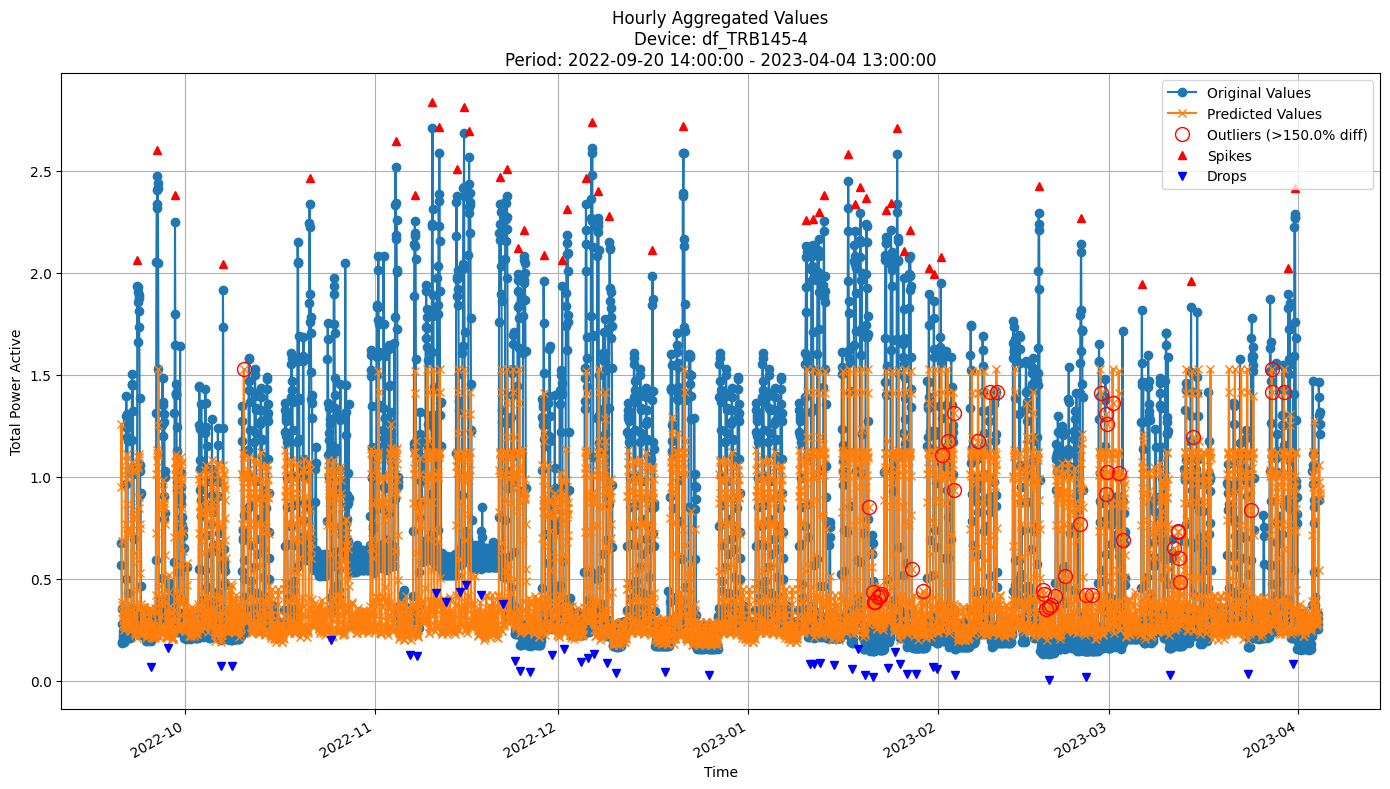


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3778
MAE: 0.2411
MAPE: 35.4197%

Directional Metrics:
Directional Accuracy: 56.3895%
First-Diff Correlation: 0.3873

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0381
  Recall: 0.0851
  F1 Score: 0.0526
Drops:
  Precision: 0.0087
  Recall: 0.0217
  F1 Score: 0.0124

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1143
  Recall: 0.2553
  F1 Score: 0.1579
Drops:
  Precision: 0.0522
  Recall: 0.1304
  F1 Score: 0.0745


In [44]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

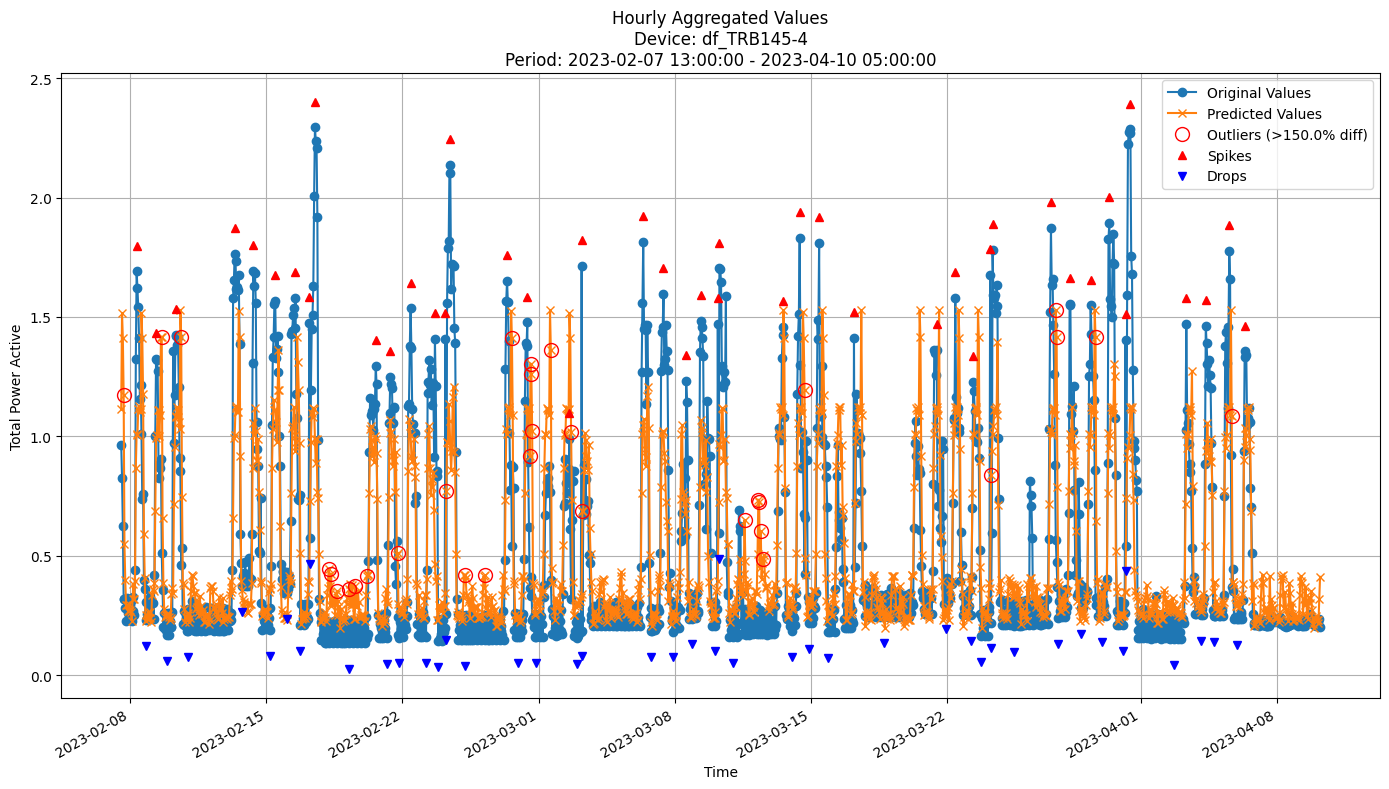


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2875
MAE: 0.1837
MAPE: 39.5551%

Directional Metrics:
Directional Accuracy: 54.4287%
First-Diff Correlation: 0.2666

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1000
  Recall: 0.0682
  F1 Score: 0.0811
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1000
  Recall: 0.0682
  F1 Score: 0.0811
Drops:
  Precision: 0.2333
  Recall: 0.1628
  F1 Score: 0.1918


In [45]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [46]:
last_valid_dates = valid[-1][0][valid[-1][0][:, 1] == "df_TRB145-4"][:, 0]
test_dates = test[0][test[0][:, 1] == "df_TRB145-4"][:, 0]
print(f"Last validation set range: {last_valid_dates[0]} - {last_valid_dates[-1]}")
print(f"Test range: {test_dates[0]} - {test_dates[-1]}")
print(f"Test set length: {len(test_dates)}")

Last validation set range: 2023-04-04 14:00:00+02:00 - 2023-04-10 05:30:00+02:00
Test range: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
Test set length: 4863


In [ ]:
# Initialize the models and params for test-set evaluation
models_classes = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
models_params = [baseline_params, gbdt_params, rf_params,
                 hoef_params, arf_hf_params, fodt_params, arf_params, incb_params]

model_test_results = {}
for model, params in zip(models_classes, models_params):
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "15m"
        print(f"\n\n\nModel: {model.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model,
        model_params=params,
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=1
    )
    model_test_results[model.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }




Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2268
	MAE: 0.0951
	MAPE: 18.9957%

Directional Metrics:
	Directional Accuracy: 9.9959%
	First-Diff Correlation: -0.1775


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-04-10 05:30:00+02:00

Time: 49.16 seconds
Predicting for chunk from 2023-04-10 06:00:00+02:00 to 2023-04-24 06:00:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-04-24 06:00:00+02:00

Time: 52.85 seconds
Predicting for chunk from 2023-04-24 06:15:00+02:00 to 2023-05-08 06:15:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-05-08 06:15:00+02:00

Time: 56.92 seconds
Predicting for chunk from 2023-05-08 06:30:00+02:00 to 2023-05-22 06:30:00+02:00

-------------------------

Retraining model on data from 2022-09-20 14:15:00+02:00 to 2023-05-22 06:30:00+02:00

Time: 61.46 seconds
Predicting for chunk from 2023-05-22 06:45:00+02:00 to 2023-05-30 21:30:00+02:00

-------------------------
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15m Metric

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2984
	MAE: 0.1844
	MAPE: 41.7364%

Directional Metrics:
	Directional Accuracy: 51.5014%
	First-Diff Correlation: 0.0659


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 60
Filtered feature count: 41
Excluded lag features: L1_act_power_lag_15min, L1_app_power_lag_15min, L1_current_lag_15min, L1_react_power_lag_15min, L1_voltage_lag_15min, L2_act_power_lag_15min, L2_app_power_lag_15min, L2_current_lag_15min, L2_react_power_lag_15min, L2_voltage_lag_15min, L3_act_power_lag_15min, L3_app_power_lag_15min, L3_current_lag_15min, L3_react_power_lag_15min, L3_voltage_lag_15min, grid_freq_lag_15min, powerfactor1_lag_15min, powerfactor2_lag_15min, powerfactor3_lag_15min
Initial training on data from 2022-09-20 14:15:00+02:00 to 2023-04-10 05:30:00+02:00
Model's memory usage: 0.000053 MB
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 06:00:00+02:00 - 2023-05-30 21:30:00+02:00
15m Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3064
	MAE: 0.1678
	MAPE: 31.7610%

Directional Metrics:
	Directional Accuracy: 39.4899%
	First-Diff Correlation: 0.0461


In [48]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [49]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [50]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
}

In [51]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [52]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n============================15-Min Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "15m")
print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, "hourly")


============================15-Min Test Results============================


Device: df_TRB145-4 | Aggregation: 15m


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.227 ± 0.000,0.095 ± 0.000,18.996 ± 0.000,9.996 ± 0.000,-17.751 ± 0.000,3.571 ± 0.000,25.000 ± 0.000,0.000 ± 0.000,6.024 ± 0.000
1,GBDT,0.206 ± 0.000,0.122 ± 0.000,27.764 ± 0.000,49.671 ± 0.000,13.960 ± 0.000,3.185 ± 0.000,19.745 ± 0.000,5.128 ± 0.000,14.744 ± 0.000
2,RandomForest,0.214 ± 0.000,0.118 ± 0.000,24.637 ± 0.000,52.530 ± 0.000,10.855 ± 0.000,3.239 ± 0.000,12.955 ± 0.000,2.449 ± 0.000,7.347 ± 0.000
3,HoeffdingTree,0.317 ± 0.000,0.186 ± 0.000,36.799 ± 0.000,28.712 ± 0.000,5.817 ± 0.000,1.093 ± 0.000,10.929 ± 0.000,3.183 ± 0.000,11.141 ± 0.000
4,ARF_Hoeffding,0.262 ± 0.000,0.154 ± 0.000,32.691 ± 0.000,46.586 ± 0.000,7.915 ± 0.000,6.278 ± 0.000,15.247 ± 0.000,1.786 ± 0.000,4.464 ± 0.000
5,FastODT,0.307 ± 0.000,0.208 ± 0.000,51.949 ± 0.000,41.937 ± 0.000,6.999 ± 0.000,3.061 ± 0.000,8.163 ± 0.000,0.000 ± 0.000,0.985 ± 0.000
6,ARF_FastODT,0.298 ± 0.000,0.184 ± 0.000,41.736 ± 0.000,51.501 ± 0.000,6.587 ± 0.000,2.778 ± 0.000,11.111 ± 0.000,0.935 ± 0.000,5.607 ± 0.000
7,IncubationBoost,0.306 ± 0.000,0.168 ± 0.000,31.761 ± 0.000,39.490 ± 0.000,4.605 ± 0.000,4.717 ± 0.000,16.981 ± 0.000,3.239 ± 0.000,8.097 ± 0.000




============================Hourly Test Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.167 ± 0.000,0.076 ± 0.000,13.770 ± 0.000,64.856 ± 0.000,35.648 ± 0.000,18.644 ± 0.000,88.136 ± 0.000,15.517 ± 0.000,41.379 ± 0.000
1,GBDT,0.174 ± 0.000,0.107 ± 0.000,23.957 ± 0.000,52.428 ± 0.000,50.094 ± 0.000,10.345 ± 0.000,65.517 ± 0.000,7.018 ± 0.000,24.561 ± 0.000
2,RandomForest,0.186 ± 0.000,0.103 ± 0.000,20.829 ± 0.000,56.543 ± 0.000,39.271 ± 0.000,10.811 ± 0.000,50.450 ± 0.000,5.505 ± 0.000,23.853 ± 0.000
3,HoeffdingTree,0.281 ± 0.000,0.169 ± 0.000,32.048 ± 0.000,54.979 ± 0.000,28.258 ± 0.000,9.859 ± 0.000,40.845 ± 0.000,5.714 ± 0.000,30.000 ± 0.000
4,ARF_Hoeffding,0.237 ± 0.000,0.143 ± 0.000,29.489 ± 0.000,59.259 ± 0.000,36.718 ± 0.000,11.765 ± 0.000,33.333 ± 0.000,10.000 ± 0.000,30.000 ± 0.000
5,FastODT,0.287 ± 0.000,0.199 ± 0.000,49.311 ± 0.000,53.333 ± 0.000,33.238 ± 0.000,9.709 ± 0.000,25.243 ± 0.000,11.881 ± 0.000,23.762 ± 0.000
6,ARF_FastODT,0.279 ± 0.000,0.176 ± 0.000,39.148 ± 0.000,58.930 ± 0.000,41.553 ± 0.000,11.009 ± 0.000,36.697 ± 0.000,5.607 ± 0.000,20.561 ± 0.000
7,IncubationBoost,0.284 ± 0.000,0.151 ± 0.000,26.556 ± 0.000,52.510 ± 0.000,30.688 ± 0.000,15.094 ± 0.000,30.189 ± 0.000,9.615 ± 0.000,26.923 ± 0.000


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Baseline</td>
      <td>0.227 ± 0.000</td>
      <td>0.095 ± 0.000</td>
      <td>18.996 ± 0.000</td>
      <td>9.996 ± 0.000</td>
      <td>-17.751 ± 0.000</td>
      <td>3.571 ± 0.000</td>
      <td>25.000 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>6.024 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>GBDT</td>
      <td>0.206 ± 0.000</td>
      <td>0.122 ± 0.000</td>
      <td>27.764 ± 0.000</td>
      <td>49.671 ± 0.000</td>
      <td>13.960 ± 0.000</td>
      <td>3.185 ± 0.000</td>
      <td>19.745 ± 0.000</td>
      <td>5.128 ± 0.000</td>
      <td>14.744 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>RandomForest</td>
      <td>0.214 ± 0.000</td>
      <td>0.118 ± 0.000</td>
      <td>24.637 ± 0.000</td>
      <td>52.530 ± 0.000</td>
      <td>10.855 ± 0.000</td>
      <td>3.239 ± 0.000</td>
      <td>12.955 ± 0.000</td>
      <td>2.449 ± 0.000</td>
      <td>7.347 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>HoeffdingTree</td>
      <td>0.317 ± 0.000</td>
      <td>0.186 ± 0.000</td>
      <td>36.799 ± 0.000</td>
      <td>28.712 ± 0.000</td>
      <td>5.817 ± 0.000</td>
      <td>1.093 ± 0.000</td>
      <td>10.929 ± 0.000</td>
      <td>3.183 ± 0.000</td>
      <td>11.141 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>ARF_Hoeffding</td>
      <td>0.262 ± 0.000</td>
      <td>0.154 ± 0.000</td>
      <td>32.691 ± 0.000</td>
      <td>46.586 ± 0.000</td>
      <td>7.915 ± 0.000</td>
      <td>6.278 ± 0.000</td>
      <td>15.247 ± 0.000</td>
      <td>1.786 ± 0.000</td>
      <td>4.464 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>FastODT</td>
      <td>0.315 ± 0.000</td>
      <td>0.204 ± 0.000</td>
      <td>47.995 ± 0.000</td>
      <td>43.871 ± 0.000</td>
      <td>5.022 ± 0.000</td>
      <td>3.571 ± 0.000</td>
      <td>19.286 ± 0.000</td>
      <td>2.214 ± 0.000</td>
      <td>6.642 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>ARF_FastODT</td>
      <td>0.385 ± 0.000</td>
      <td>0.245 ± 0.000</td>
      <td>49.006 ± 0.000</td>
      <td>52.612 ± 0.000</td>
      <td>5.481 ± 0.000</td>
      <td>3.540 ± 0.000</td>
      <td>14.159 ± 0.000</td>
      <td>0.000 ± 0.000</td>
      <td>6.278 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>IncubationBoost</td>
      <td>0.382 ± 0.000</td>
      <td>0.217 ± 0.000</td>
      <td>34.076 ± 0.000</td>
      <td>42.925 ± 0.000</td>
      <td>7.258 ± 0.000</td>
      <td>5.900 ± 0.000</td>
      <td>14.749 ± 0.000</td>
      <td>5.521 ± 0.000</td>
      <td>10.429 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Baseline</td>
      <td>0.167 ± 0.000</td>
      <td>0.076 ± 0.000</td>
      <td>13.770 ± 0.000</td>
      <td>64.856 ± 0.000</td>
      <td>35.648 ± 0.000</td>
      <td>18.644 ± 0.000</td>
      <td>88.136 ± 0.000</td>
      <td>15.517 ± 0.000</td>
      <td>41.379 ± 0.000</td>
    </tr>
    <tr>
      <th>1</th>
      <td>GBDT</td>
      <td>0.174 ± 0.000</td>
      <td>0.107 ± 0.000</td>
      <td>23.957 ± 0.000</td>
      <td>52.428 ± 0.000</td>
      <td>50.094 ± 0.000</td>
      <td>10.345 ± 0.000</td>
      <td>65.517 ± 0.000</td>
      <td>7.018 ± 0.000</td>
      <td>24.561 ± 0.000</td>
    </tr>
    <tr>
      <th>2</th>
      <td>RandomForest</td>
      <td>0.186 ± 0.000</td>
      <td>0.103 ± 0.000</td>
      <td>20.829 ± 0.000</td>
      <td>56.543 ± 0.000</td>
      <td>39.271 ± 0.000</td>
      <td>10.811 ± 0.000</td>
      <td>50.450 ± 0.000</td>
      <td>5.505 ± 0.000</td>
      <td>23.853 ± 0.000</td>
    </tr>
    <tr>
      <th>3</th>
      <td>HoeffdingTree</td>
      <td>0.281 ± 0.000</td>
      <td>0.169 ± 0.000</td>
      <td>32.048 ± 0.000</td>
      <td>54.979 ± 0.000</td>
      <td>28.258 ± 0.000</td>
      <td>9.859 ± 0.000</td>
      <td>40.845 ± 0.000</td>
      <td>5.714 ± 0.000</td>
      <td>30.000 ± 0.000</td>
    </tr>
    <tr>
      <th>4</th>
      <td>ARF_Hoeffding</td>
      <td>0.237 ± 0.000</td>
      <td>0.143 ± 0.000</td>
      <td>29.489 ± 0.000</td>
      <td>59.259 ± 0.000</td>
      <td>36.718 ± 0.000</td>
      <td>11.765 ± 0.000</td>
      <td>33.333 ± 0.000</td>
      <td>10.000 ± 0.000</td>
      <td>30.000 ± 0.000</td>
    </tr>
    <tr>
      <th>5</th>
      <td>FastODT</td>
      <td>0.295 ± 0.000</td>
      <td>0.195 ± 0.000</td>
      <td>45.338 ± 0.000</td>
      <td>51.770 ± 0.000</td>
      <td>42.868 ± 0.000</td>
      <td>12.613 ± 0.000</td>
      <td>30.631 ± 0.000</td>
      <td>7.273 ± 0.000</td>
      <td>20.000 ± 0.000</td>
    </tr>
    <tr>
      <th>6</th>
      <td>ARF_FastODT</td>
      <td>0.372 ± 0.000</td>
      <td>0.239 ± 0.000</td>
      <td>46.934 ± 0.000</td>
      <td>57.449 ± 0.000</td>
      <td>39.784 ± 0.000</td>
      <td>13.592 ± 0.000</td>
      <td>34.951 ± 0.000</td>
      <td>3.960 ± 0.000</td>
      <td>9.901 ± 0.000</td>
    </tr>
    <tr>
      <th>7</th>
      <td>IncubationBoost</td>
      <td>0.367 ± 0.000</td>
      <td>0.210 ± 0.000</td>
      <td>32.500 ± 0.000</td>
      <td>57.037 ± 0.000</td>
      <td>41.255 ± 0.000</td>
      <td>10.084 ± 0.000</td>
      <td>35.294 ± 0.000</td>
      <td>1.709 ± 0.000</td>
      <td>13.675 ± 0.000</td>
    </tr>
  </tbody>
</table>
</div>

## Validation results

In [53]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n============================15-Min Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "15m")
print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, "hourly")


============================15-Min Validation Results============================


Device: df_TRB145-4 | Aggregation: 15m


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.199 ± 0.037,0.101 ± 0.023,20.216 ± 5.626,11.642 ± 1.367,6.437 ± 3.930,7.001 ± 4.468,20.457 ± 8.280,6.641 ± 3.243,18.536 ± 4.573
1,GBDT,0.236 ± 0.052,0.150 ± 0.037,35.297 ± 7.282,53.728 ± 4.308,15.084 ± 8.595,7.258 ± 5.042,13.154 ± 7.693,4.276 ± 5.013,11.144 ± 8.907
2,RandomForest,0.119 ± 0.016,0.070 ± 0.011,13.961 ± 2.756,65.509 ± 1.986,70.419 ± 7.178,31.743 ± 7.532,50.338 ± 11.320,5.821 ± 3.905,16.184 ± 8.821
3,HoeffdingTree,0.335 ± 0.088,0.225 ± 0.068,47.040 ± 9.681,24.942 ± 0.969,4.272 ± 3.119,3.553 ± 1.856,13.362 ± 5.051,2.371 ± 2.319,6.278 ± 4.974
4,ARF_Hoeffding,0.279 ± 0.081,0.192 ± 0.057,42.644 ± 8.561,44.084 ± 1.075,9.471 ± 5.891,4.792 ± 3.282,13.950 ± 6.182,2.449 ± 3.715,5.764 ± 7.244
5,FastODT,0.376 ± 0.115,0.273 ± 0.073,57.015 ± 13.904,37.600 ± 3.900,6.850 ± 3.878,2.787 ± 2.532,8.362 ± 2.973,3.694 ± 1.155,7.274 ± 2.242
6,ARF_FastODT,0.332 ± 0.075,0.257 ± 0.063,66.337 ± 19.073,49.389 ± 0.843,8.426 ± 2.953,4.390 ± 1.732,10.498 ± 5.227,0.000 ± 0.000,2.313 ± 1.715
7,IncubationBoost,0.424 ± 0.181,0.292 ± 0.154,45.219 ± 10.868,34.617 ± 3.562,7.143 ± 2.053,3.019 ± 1.598,10.100 ± 2.624,1.770 ± 1.907,6.280 ± 2.609




============================Hourly Validation Results============================


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.173 ± 0.032,0.095 ± 0.022,18.499 ± 5.193,57.673 ± 4.592,47.969 ± 8.661,23.774 ± 4.590,78.282 ± 12.580,12.656 ± 4.308,51.619 ± 10.709
1,GBDT,0.207 ± 0.048,0.135 ± 0.034,30.762 ± 6.747,62.167 ± 7.159,45.288 ± 15.158,15.784 ± 11.166,49.615 ± 11.706,16.309 ± 10.757,31.620 ± 11.778
2,RandomForest,0.096 ± 0.015,0.056 ± 0.009,10.342 ± 2.092,80.169 ± 2.617,86.434 ± 3.957,47.381 ± 12.455,82.644 ± 5.878,25.023 ± 6.721,39.065 ± 8.388
3,HoeffdingTree,0.297 ± 0.085,0.203 ± 0.064,41.242 ± 7.638,51.434 ± 3.039,25.629 ± 15.502,11.596 ± 8.887,40.356 ± 10.445,5.666 ± 8.283,20.243 ± 8.353
4,ARF_Hoeffding,0.255 ± 0.079,0.179 ± 0.055,38.363 ± 6.662,54.794 ± 5.816,41.154 ± 15.673,21.472 ± 9.945,50.191 ± 12.069,5.687 ± 6.362,18.026 ± 10.530
5,FastODT,0.360 ± 0.115,0.265 ± 0.073,53.605 ± 12.465,54.248 ± 2.711,40.781 ± 11.232,12.942 ± 10.085,42.802 ± 14.570,8.318 ± 5.462,23.616 ± 13.939
6,ARF_FastODT,0.315 ± 0.075,0.248 ± 0.061,62.334 ± 18.478,58.545 ± 3.559,47.789 ± 11.204,15.439 ± 4.723,44.507 ± 14.404,3.048 ± 2.919,12.578 ± 9.417
7,IncubationBoost,0.408 ± 0.185,0.282 ± 0.158,41.557 ± 11.755,54.930 ± 2.904,37.390 ± 9.919,14.138 ± 6.007,34.522 ± 17.251,3.932 ± 3.044,13.755 ± 8.984


<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Baseline</td>
      <td>0.199 ± 0.037</td>
      <td>0.101 ± 0.023</td>
      <td>20.216 ± 5.626</td>
      <td>11.642 ± 1.367</td>
      <td>6.437 ± 3.930</td>
      <td>7.001 ± 4.468</td>
      <td>20.457 ± 8.280</td>
      <td>6.641 ± 3.243</td>
      <td>18.536 ± 4.573</td>
    </tr>
    <tr>
      <th>1</th>
      <td>GBDT</td>
      <td>0.236 ± 0.052</td>
      <td>0.150 ± 0.037</td>
      <td>35.297 ± 7.282</td>
      <td>53.728 ± 4.308</td>
      <td>15.084 ± 8.595</td>
      <td>7.258 ± 5.042</td>
      <td>13.154 ± 7.693</td>
      <td>4.276 ± 5.013</td>
      <td>11.144 ± 8.907</td>
    </tr>
    <tr>
      <th>2</th>
      <td>RandomForest</td>
      <td>0.119 ± 0.016</td>
      <td>0.070 ± 0.011</td>
      <td>13.961 ± 2.756</td>
      <td>65.509 ± 1.986</td>
      <td>70.419 ± 7.178</td>
      <td>31.743 ± 7.532</td>
      <td>50.338 ± 11.320</td>
      <td>5.821 ± 3.905</td>
      <td>16.184 ± 8.821</td>
    </tr>
    <tr>
      <th>3</th>
      <td>HoeffdingTree</td>
      <td>0.335 ± 0.088</td>
      <td>0.225 ± 0.068</td>
      <td>47.040 ± 9.681</td>
      <td>24.942 ± 0.969</td>
      <td>4.272 ± 3.119</td>
      <td>3.553 ± 1.856</td>
      <td>13.362 ± 5.051</td>
      <td>2.371 ± 2.319</td>
      <td>6.278 ± 4.974</td>
    </tr>
    <tr>
      <th>4</th>
      <td>ARF_Hoeffding</td>
      <td>0.279 ± 0.081</td>
      <td>0.192 ± 0.057</td>
      <td>42.644 ± 8.561</td>
      <td>44.084 ± 1.075</td>
      <td>9.471 ± 5.891</td>
      <td>4.792 ± 3.282</td>
      <td>13.950 ± 6.182</td>
      <td>2.449 ± 3.715</td>
      <td>5.764 ± 7.244</td>
    </tr>
    <tr>
      <th>5</th>
      <td>FastODT</td>
      <td>0.417 ± 0.141</td>
      <td>0.290 ± 0.088</td>
      <td>55.319 ± 11.888</td>
      <td>40.029 ± 3.254</td>
      <td>3.788 ± 4.350</td>
      <td>1.879 ± 1.869</td>
      <td>12.162 ± 4.701</td>
      <td>4.680 ± 3.537</td>
      <td>8.764 ± 6.135</td>
    </tr>
    <tr>
      <th>6</th>
      <td>ARF_FastODT</td>
      <td>0.457 ± 0.129</td>
      <td>0.349 ± 0.098</td>
      <td>84.814 ± 40.570</td>
      <td>50.521 ± 1.915</td>
      <td>7.897 ± 2.451</td>
      <td>2.375 ± 3.183</td>
      <td>6.645 ± 4.907</td>
      <td>0.433 ± 1.060</td>
      <td>3.401 ± 4.203</td>
    </tr>
    <tr>
      <th>7</th>
      <td>IncubationBoost</td>
      <td>0.480 ± 0.158</td>
      <td>0.323 ± 0.141</td>
      <td>41.967 ± 11.346</td>
      <td>39.107 ± 3.311</td>
      <td>6.576 ± 3.891</td>
      <td>3.915 ± 2.053</td>
      <td>11.328 ± 3.451</td>
      <td>1.965 ± 1.289</td>
      <td>6.839 ± 3.850</td>
    </tr>
  </tbody>
</table>
</div>

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>Model</th>
      <th>RMSE</th>
      <th>MAE</th>
      <th>MAPE (%)</th>
      <th>Directional Accuracy (%)</th>
      <th>First Diff Corr (%)</th>
      <th>Spikes Immediate F1 (%)</th>
      <th>Spikes Delayed F1 (%)</th>
      <th>Drops Immediate F1 (%)</th>
      <th>Drops Delayed F1 (%)</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>Baseline</td>
      <td>0.173 ± 0.032</td>
      <td>0.095 ± 0.022</td>
      <td>18.499 ± 5.193</td>
      <td>57.673 ± 4.592</td>
      <td>47.969 ± 8.661</td>
      <td>23.774 ± 4.590</td>
      <td>78.282 ± 12.580</td>
      <td>12.656 ± 4.308</td>
      <td>51.619 ± 10.709</td>
    </tr>
    <tr>
      <th>1</th>
      <td>GBDT</td>
      <td>0.207 ± 0.048</td>
      <td>0.135 ± 0.034</td>
      <td>30.762 ± 6.747</td>
      <td>62.167 ± 7.159</td>
      <td>45.288 ± 15.158</td>
      <td>15.784 ± 11.166</td>
      <td>49.615 ± 11.706</td>
      <td>16.309 ± 10.757</td>
      <td>31.620 ± 11.778</td>
    </tr>
    <tr>
      <th>2</th>
      <td>RandomForest</td>
      <td>0.096 ± 0.015</td>
      <td>0.056 ± 0.009</td>
      <td>10.342 ± 2.092</td>
      <td>80.169 ± 2.617</td>
      <td>86.434 ± 3.957</td>
      <td>47.381 ± 12.455</td>
      <td>82.644 ± 5.878</td>
      <td>25.023 ± 6.721</td>
      <td>39.065 ± 8.388</td>
    </tr>
    <tr>
      <th>3</th>
      <td>HoeffdingTree</td>
      <td>0.297 ± 0.085</td>
      <td>0.203 ± 0.064</td>
      <td>41.242 ± 7.638</td>
      <td>51.434 ± 3.039</td>
      <td>25.629 ± 15.502</td>
      <td>11.596 ± 8.887</td>
      <td>40.356 ± 10.445</td>
      <td>5.666 ± 8.283</td>
      <td>20.243 ± 8.353</td>
    </tr>
    <tr>
      <th>4</th>
      <td>ARF_Hoeffding</td>
      <td>0.255 ± 0.079</td>
      <td>0.179 ± 0.055</td>
      <td>38.363 ± 6.662</td>
      <td>54.794 ± 5.816</td>
      <td>41.154 ± 15.673</td>
      <td>21.472 ± 9.945</td>
      <td>50.191 ± 12.069</td>
      <td>5.687 ± 6.362</td>
      <td>18.026 ± 10.530</td>
    </tr>
    <tr>
      <th>5</th>
      <td>FastODT</td>
      <td>0.402 ± 0.142</td>
      <td>0.283 ± 0.089</td>
      <td>52.129 ± 10.785</td>
      <td>53.932 ± 4.874</td>
      <td>35.066 ± 11.034</td>
      <td>13.729 ± 9.490</td>
      <td>36.516 ± 12.908</td>
      <td>8.955 ± 13.287</td>
      <td>21.462 ± 15.535</td>
    </tr>
    <tr>
      <th>6</th>
      <td>ARF_FastODT</td>
      <td>0.446 ± 0.130</td>
      <td>0.343 ± 0.098</td>
      <td>81.297 ± 39.955</td>
      <td>55.394 ± 6.127</td>
      <td>41.407 ± 12.011</td>
      <td>14.480 ± 9.212</td>
      <td>40.114 ± 10.949</td>
      <td>11.396 ± 17.375</td>
      <td>25.747 ± 18.035</td>
    </tr>
    <tr>
      <th>7</th>
      <td>IncubationBoost</td>
      <td>0.468 ± 0.159</td>
      <td>0.317 ± 0.143</td>
      <td>40.581 ± 12.278</td>
      <td>56.457 ± 1.548</td>
      <td>42.596 ± 8.917</td>
      <td>6.584 ± 4.019</td>
      <td>32.647 ± 15.742</td>
      <td>3.123 ± 2.880</td>
      <td>21.965 ± 12.217</td>
    </tr>
  </tbody>
</table>
</div>

### By-period validation results

In [54]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (**higher is better**)


In [55]:
print("\n\n=============================15-Min Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15m",
    metric_name="dir_accuracy",
    display_gain=True
)
print("\n\n\n=============================Hourly Directional Accuracy per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)



=============================15-Min Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15m | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,11.202,53.256,55.043,23.670,42.799,39.859,50.056,34.537,38.802750
Period 2,11.537,52.066,52.773,23.930,43.878,38.407,48.753,37.067,38.551375
Period 3,14.217,63.751,59.806,25.530,44.920,29.029,50.800,26.312,39.295625
Period 4,11.835,53.852,52.438,24.339,44.994,38.593,49.200,37.365,39.077000
Period 5,12.430,51.619,53.182,26.610,44.957,38.035,49.051,36.584,39.058500
Period 6,10.867,52.289,50.540,25.605,42.203,36.658,48.046,36.137,37.793125
Period 7,9.410,49.262,53.690,24.908,44.834,42.620,49.815,34.317,38.607000



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.335,-1.190,-2.270,0.260,1.079,-1.452,-1.303,2.530,-0.251
Period 3 - Period 2,2.680,11.685,7.033,1.600,1.042,-9.378,2.047,-10.755,0.744
Period 4 - Period 3,-2.382,-9.899,-7.368,-1.191,0.074,9.564,-1.600,11.053,-0.219
Period 5 - Period 4,0.595,-2.233,0.744,2.271,-0.037,-0.558,-0.149,-0.781,-0.018
Period 6 - Period 5,-1.563,0.670,-2.642,-1.005,-2.754,-1.377,-1.005,-0.447,-1.265
Period 7 - Period 6,-1.457,-3.027,3.150,-0.697,2.631,5.962,1.769,-1.820,0.814





=============================Hourly Directional Accuracy per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,53.353,64.680,65.723,53.651,56.632,57.228,55.738,54.993,57.749750
Period 2,58.867,57.526,54.098,50.671,59.314,56.334,58.718,58.122,56.706250
Period 3,67.362,73.323,68.852,56.334,62.444,57.377,66.170,54.247,63.263625
Period 4,59.314,67.362,56.185,48.882,50.373,54.247,59.165,58.271,56.724875
Period 5,55.738,65.276,63.487,47.541,52.161,53.055,57.079,54.396,56.091625
Period 6,56.483,56.632,51.416,48.882,44.113,51.863,58.867,55.589,52.980625
Period 7,52.593,50.370,61.481,54.074,58.519,49.630,54.074,48.889,53.703750



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.514,-7.154,-11.625,-2.980,2.682,-0.894,2.980,3.129,-1.044
Period 3 - Period 2,8.495,15.797,14.754,5.663,3.130,1.043,7.452,-3.875,6.557
Period 4 - Period 3,-8.048,-5.961,-12.667,-7.452,-12.071,-3.130,-7.005,4.024,-6.539
Period 5 - Period 4,-3.576,-2.086,7.302,-1.341,1.788,-1.192,-2.086,-3.875,-0.633
Period 6 - Period 5,0.745,-8.644,-12.071,1.341,-8.048,-1.192,1.788,1.193,-3.111
Period 7 - Period 6,-3.890,-6.262,10.065,5.192,14.406,-2.233,-4.793,-6.700,0.723


#### MAPE (**lower is better**)

In [56]:
print("\n\n=============================15-Min MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15m",
    metric_name="mape",
    display_gain=True
)
print("\n\n\n=============================Hourly MAPE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)



=============================15-Min MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15m | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,14.204,24.086,23.763,41.892,31.878,38.748,36.925,64.806,34.537750
Period 2,19.682,34.536,31.743,46.602,42.098,48.247,98.259,49.608,46.346875
Period 3,16.251,27.830,24.297,37.878,32.053,39.091,51.657,29.960,32.377125
Period 4,26.170,47.250,42.235,53.107,51.805,69.779,78.752,45.331,51.803625
Period 5,27.567,37.648,39.918,63.567,55.522,76.099,62.808,50.887,51.752000
Period 6,24.987,34.154,33.876,53.232,46.749,61.536,56.252,43.158,44.243000
Period 7,12.654,41.574,31.297,33.001,38.401,65.605,79.704,32.782,41.877250



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,5.478,10.450,7.980,4.710,10.220,9.499,61.334,-15.198,11.809
Period 3 - Period 2,-3.431,-6.706,-7.446,-8.724,-10.045,-9.156,-46.602,-19.648,-13.970
Period 4 - Period 3,9.919,19.420,17.938,15.229,19.752,30.688,27.095,15.371,19.427
Period 5 - Period 4,1.397,-9.602,-2.317,10.460,3.717,6.320,-15.944,5.556,-0.052
Period 6 - Period 5,-2.580,-3.494,-6.042,-10.335,-8.773,-14.563,-6.556,-7.729,-7.509
Period 7 - Period 6,-12.333,7.420,-2.579,-20.231,-8.348,4.069,23.452,-10.376,-2.366





=============================Hourly MAPE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,13.404,21.579,21.695,38.583,30.425,38.251,35.030,64.948,32.989375
Period 2,17.982,29.765,26.905,41.229,38.121,45.697,93.574,48.854,42.765875
Period 3,14.942,24.913,21.007,32.779,28.979,36.594,48.907,28.331,29.556500
Period 4,23.444,40.705,35.097,45.296,44.786,63.618,71.892,38.430,45.408500
Period 5,25.767,31.174,32.994,54.485,48.919,70.210,57.179,44.181,45.613625
Period 6,22.806,27.118,27.998,45.870,40.479,56.507,51.506,37.042,38.665750
Period 7,11.147,40.082,29.506,30.453,36.828,64.357,78.247,29.113,39.966625



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,4.578,8.186,5.210,2.646,7.696,7.446,58.544,-16.094,9.777
Period 3 - Period 2,-3.040,-4.852,-5.898,-8.450,-9.142,-9.103,-44.667,-20.523,-13.209
Period 4 - Period 3,8.502,15.792,14.090,12.517,15.807,27.024,22.985,10.099,15.852
Period 5 - Period 4,2.323,-9.531,-2.103,9.189,4.133,6.592,-14.713,5.751,0.205
Period 6 - Period 5,-2.961,-4.056,-4.996,-8.615,-8.440,-13.703,-5.673,-7.139,-6.948
Period 7 - Period 6,-11.659,12.964,1.508,-15.417,-3.651,7.850,26.741,-7.929,1.301


#### RMSE (**lower is better**)

In [57]:
print("\n\n=============================15-Min RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL="15m",
    metric_name="rmse",
    display_gain=True
)
print("\n\n\n=============================Hourly RMSE per period and gain/drop=============================")
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)



=============================15-Min RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: 15m | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.217,0.327,0.303,0.470,0.403,0.533,0.417,0.703,0.421625
Period 2,0.236,0.280,0.270,0.401,0.336,0.531,0.453,0.679,0.398250
Period 3,0.163,0.177,0.159,0.251,0.187,0.297,0.257,0.338,0.228625
Period 4,0.230,0.253,0.250,0.349,0.308,0.425,0.363,0.425,0.325375
Period 5,0.205,0.205,0.231,0.355,0.295,0.330,0.309,0.327,0.282125
Period 6,0.215,0.241,0.240,0.340,0.281,0.313,0.291,0.317,0.279750
Period 7,0.125,0.171,0.148,0.179,0.144,0.205,0.238,0.181,0.173875



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.019,-0.047,-0.033,-0.069,-0.067,-0.002,0.036,-0.024,-0.023
Period 3 - Period 2,-0.073,-0.103,-0.111,-0.150,-0.149,-0.234,-0.196,-0.341,-0.170
Period 4 - Period 3,0.067,0.076,0.091,0.098,0.121,0.128,0.106,0.087,0.097
Period 5 - Period 4,-0.025,-0.048,-0.019,0.006,-0.013,-0.095,-0.054,-0.098,-0.043
Period 6 - Period 5,0.010,0.036,0.009,-0.015,-0.014,-0.017,-0.018,-0.010,-0.002
Period 7 - Period 6,-0.090,-0.070,-0.092,-0.161,-0.137,-0.108,-0.053,-0.136,-0.106





=============================Hourly RMSE per period and gain/drop=============================

Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.183,0.296,0.275,0.437,0.383,0.518,0.399,0.693,0.398000
Period 2,0.207,0.246,0.238,0.354,0.307,0.516,0.437,0.668,0.371625
Period 3,0.143,0.153,0.137,0.214,0.164,0.285,0.241,0.326,0.207875
Period 4,0.203,0.223,0.224,0.310,0.283,0.408,0.344,0.409,0.300500
Period 5,0.180,0.175,0.207,0.316,0.271,0.309,0.290,0.303,0.256375
Period 6,0.185,0.199,0.206,0.291,0.251,0.289,0.269,0.292,0.247750
Period 7,0.111,0.158,0.134,0.155,0.130,0.192,0.226,0.163,0.158625



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.024,-0.050,-0.037,-0.083,-0.076,-0.002,0.038,-0.025,-0.026
Period 3 - Period 2,-0.064,-0.093,-0.101,-0.140,-0.143,-0.231,-0.196,-0.342,-0.164
Period 4 - Period 3,0.060,0.070,0.087,0.096,0.119,0.123,0.103,0.083,0.093
Period 5 - Period 4,-0.023,-0.048,-0.017,0.006,-0.012,-0.099,-0.054,-0.106,-0.044
Period 6 - Period 5,0.005,0.024,-0.001,-0.025,-0.020,-0.020,-0.021,-0.011,-0.009
Period 7 - Period 6,-0.074,-0.041,-0.072,-0.136,-0.121,-0.097,-0.043,-0.129,-0.089
